# Delta Hedging of European Options under Model Misspecification
### Hedging Error Analysis, Transaction Costs and Empirical Backtesting

Mehta Prem (2024ADPS0851G), MAC F244 Stochastic Calculus and Application to Finance, BITS Pilani K K Birla Goa Campus.

## The problem

The Black-Scholes-Merton (BSM) model says a European option can be replicated exactly by holding $\Delta(t)$ shares and rebalancing continuously. That needs three things that do not hold in practice: continuous trading, no transaction costs, and a stock following geometric Brownian motion (GBM) with a known constant volatility. This notebook measures how large and how risky the hedging error of a **short at-the-money call** becomes when each assumption is relaxed, and compares the simulations with a backtest on NIFTY 50. The hedger is the seller of the call.

## Models and notation (as in the class notes)

- **Base model:** $dS(t) = \alpha S(t)\,dt + \sigma S(t)\,dW(t)$, $S(t) = S_0\exp\{\sigma W(t) + (\alpha - \tfrac12\sigma^2)t\}$. The hedge ratio is $\Delta(t) = C_x(t, S(t))$ with $C_x = N(d_+)$ and gamma $C_{xx} = N'(d_+)/(x\sigma\sqrt\tau)$, $\tau = T - t$.
- **Discrete hedging error:** per step about $\tfrac12 C_{xx}\sigma^2S^2\big[(\Delta W(t_i))^2 - \Delta t_i\big]$, nonzero because $(\Delta W)^2 \ne \Delta t$ at a finite step, so the total standard deviation scales like $\sqrt{\Delta t}$ (quadratic variation $[W,W](T) = T$).
- **Wrong volatility:** hedging at $\sigma_h$ while the stock has volatility $\sigma$ gives the seller the discounted terminal P&L $\tfrac12(\sigma_h^2 - \sigma^2)\int_0^T e^{-rt}S^2C_{xx}\,dt$, positive when $\sigma_h > \sigma$.
- **Wrong dynamics and costs:** Heston stochastic volatility (the variance is the CIR process of the notes, simulated by full-truncation Euler), the Merton jump-diffusion, and Leland's transaction-cost result $\hat\sigma_L^2 = \sigma^2\big(1 + \sqrt{2/\pi}\,k/(\sigma\sqrt{\Delta t})\big)$, with BSM Deltas still used for the hedge.

## Experiments

| ID | Varies | Compared with |
| --- | --- | --- |
| E1 | number of rebalancing dates $n$ | slope $-1/2$ on a log-log plot |
| E2 | hedge volatility $\sigma_h$ | wrong-volatility formula |
| E3 | Heston vol-of-vol and correlation | GBM baseline |
| E4 | Merton jump intensity and size | GBM baseline |
| E5 | cost rate $k$ and $n$ | Leland scaling |
| E6 | strike and maturity | gamma profile and the Itô error formula |
| E7 | real NIFTY 50 backtest on listed NSE option prices (2015 to 2026), with a baseline pricing the same options at India VIX | simulated GBM and Heston |

Base case unless stated: $S_0 = K = 100$, $\alpha = r = 5\%$, $\sigma = 20\%$, $T = 1$, 20,000 paths, seed 42. Every cell below runs the code in `src/` and `experiments/`; nothing is edited by hand.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

FIGURES = ROOT / "results" / "figures"
TABLES = ROOT / "results" / "tables"


def run_experiment(name):
    """Import experiments/<name>.py and run its main(), which prints its tables and saves its figures."""
    spec = importlib.util.spec_from_file_location(name, ROOT / "experiments" / f"{name}.py")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    module.main()


def show_figures(*names):
    """Display saved figures from results/figures inline."""
    for name in names:
        display(Image(filename=str(FIGURES / f"{name}.png"), width=900))


def show_table(name):
    """Display a saved table from results/tables inline."""
    display(pd.read_csv(TABLES / f"{name}.csv"))

## Step 2: BSM equation, price, Delta, Theta and Gamma (src/bs.py)

**Concept (derivation in the order of the notes).** The stock is $dS(t) = \alpha S(t)\,dt + \sigma S(t)\,dW(t)$. A hedger holds $\Delta(t)$ shares and the rest of the wealth $X(t)$ in the money market at rate $r$:

$$dX(t) = r\big(X(t) - \Delta(t)S(t)\big)dt + \Delta(t)\,dS(t) = rX(t)\,dt + \Delta(t)(\alpha - r)S(t)\,dt + \sigma\Delta(t)S(t)\,dW(t).$$

Discounted wealth satisfies $d\big(e^{-rt}X(t)\big) = \Delta(t)\,d\big(e^{-rt}S(t)\big)$. Now apply the Itô formula to $e^{-rt}C(t, S(t))$:

$$d\big(e^{-rt}C\big) = e^{-rt}\Big[-rC + C_t + \alpha S C_x + \tfrac12\sigma^2S^2C_{xx}\Big]dt + e^{-rt}\sigma S C_x\,dW.$$

Require $X(t) = C(t, S(t))$ for all $t$, starting from $X(0) = C(0, S_0)$. Matching the $dW$ terms gives $\Delta(t) = C_x(t, S(t))$; matching the $dt$ terms then gives the BSM equation

$$rC(t,x) = C_t(t,x) + rxC_x(t,x) + \tfrac12\sigma^2x^2C_{xx}(t,x), \qquad C(T,x) = (x-K)^+,$$

with $C(t,0) = 0$ and $\lim_{x\to\infty}\big[C(t,x) - (x - Ke^{-r(T-t)})\big] = 0$. The drift $\alpha$ cancels, so the price does not depend on it.

**Solution and Greeks.** With $\tau = T - t$,

$$d_\pm(\tau, x) = \frac{1}{\sigma\sqrt\tau}\Big[\log\frac{x}{K} + \Big(r \pm \frac{\sigma^2}{2}\Big)\tau\Big], \quad d_- = d_+ - \sigma\sqrt\tau, \quad C(t,x) = xN(d_+) - Ke^{-r\tau}N(d_-),$$

$$C_x = N(d_+), \qquad C_t = -rKe^{-r\tau}N(d_-) - \frac{x\sigma}{2\sqrt\tau}N'(d_+), \qquad C_{xx} = \frac{N'(d_+)}{x\sigma\sqrt\tau}.$$

The notes name gamma as $C_{xx}$ but I could not read its closed form off the pages, so I derived it from $C_x = N(d_+)$: $d_+$ depends on $x$ only through $\log(x/K)$, so $\partial d_+/\partial x = 1/(x\sigma\sqrt\tau)$ and $C_{xx} = N'(d_+)/(x\sigma\sqrt\tau)$. The test suite confirms it against a finite difference.

$C_{xx}$ is the key quantity for hedging error: the hedge ratio changes by about $C_{xx}\,dS$, so a large gamma means the hedge goes stale quickly when rebalancing is discrete.

**Result.** For $x = K = 100$, $r = 5\%$, $\sigma = 20\%$, $\tau = 1$: $C = 10.4506$ (the standard closed-form value), $C_x = 0.6368$, $C_t = -6.4140$, $C_{xx} = 0.01876$. The BSM equation holds numerically: $rC = 0.52253$ and $C_t + rxC_x + \tfrac12\sigma^2x^2C_{xx} = 0.52253$. The tests check put-call parity ($C - P = x - Ke^{-r\tau}$), $C_x \in (0,1)$, $C_x$, $C_t$ and $C_{xx}$ against finite differences, the BSM equation, and the boundary conditions. The BSM-equation test checks that the code satisfies the equation the theory is built on, not just that it reproduces one number.

In [2]:
import numpy as np

from src import bs

x, K, r, sigma, tau = 100.0, 100.0, 0.05, 0.2, 1.0
C = float(bs.call_price(x, K, r, sigma, tau))
C_x, C_t, C_xx = (float(f(x, K, r, sigma, tau)) for f in (bs.call_delta, bs.call_theta, bs.gamma))
P = float(bs.put_price(x, K, r, sigma, tau))
print(f"C(t, x)  = {C:.4f}   (standard closed-form value 10.4506)")
print(f"C_x      = {C_x:.4f}")
print(f"C_t      = {C_t:.4f}")
print(f"C_xx     = {C_xx:.5f}")
print(f"BSM equation: r C = {r * C:.6f},  C_t + r x C_x + 0.5 sigma^2 x^2 C_xx = {C_t + r * x * C_x + 0.5 * sigma**2 * x**2 * C_xx:.6f}")
print(f"put-call parity: C - P = {C - P:.6f},  x - K exp(-r tau) = {x - K * np.exp(-r * tau):.6f}")

C(t, x)  = 10.4506   (standard closed-form value 10.4506)
C_x      = 0.6368
C_t      = -6.4140
C_xx     = 0.01876
BSM equation: r C = 0.522529,  C_t + r x C_x + 0.5 sigma^2 x^2 C_xx = 0.522529
put-call parity: C - P = 4.877058,  x - K exp(-r tau) = 4.877058


**Interpretation.** The price matches the standard closed-form value 10.4506, and the closed-form Greeks satisfy the BSM equation $rC = C_t + rxC_x + \tfrac12\sigma^2x^2C_{xx}$ to machine precision, which is the equation the whole project is built on. $C_x$ lies strictly between 0 and 1 and put-call parity holds. The test suite at the end of this notebook also checks $C_x$, $C_t$ and $C_{xx}$ against finite differences and the boundary conditions.

## Step 3: GBM simulator and hedging engine (src/simulators.py, src/hedging.py)

**Concept.** Geometric Brownian motion has the exact solution

$$S(t) = S_0\exp\Big\{\sigma W(t) + \big(\alpha - \tfrac12\sigma^2\big)t\Big\}, \quad E[S(t)] = S_0e^{\alpha t}, \quad \mathrm{Var}(S(t)) = S_0^2e^{2\alpha t}\big(e^{\sigma^2t} - 1\big),$$

so paths are sampled from it on the grid $0 = t_0 < t_1 < \dots < t_n = T$ with $\Delta W(t_i) \sim N(0, \Delta t_i)$. This is exact: there is no discretisation error, and every hedging error we see comes from the hedging, not the simulation. The simulated mean and variance are tested against the two formulas above.

The hedger is the seller of the call. The seller receives $X(0) = C(0, S_0)$, holds $\Delta(t_i)$ shares, and keeps the rest in the money market at rate $r$. Self-financing means the only cash flows after time 0 are share trades:

$$\text{cash}_i = \text{cash}_{i-1}e^{r\Delta t_{i-1}} - \big(\Delta(t_i) - \Delta(t_{i-1})\big)S(t_i), \qquad \text{P\&L} = X(T) - (S(T) - K)^+ = \text{cash}_n + \Delta(t_{n-1})S(T) - (S(T)-K)^+.$$

If the hedge could be rebalanced continuously under GBM, this would be exactly 0 (replication, Step 2). With $n$ finite dates the portfolio is only hedged to first order between dates, and the second-order term $\tfrac12 C_{xx}(\Delta S)^2$ is what is left over.

**Result.** $S_0 = K = 100$, $\alpha = r = 5\%$, $\sigma = 20\%$, $T = 1$, 20,000 paths, seed 42:

| n | mean P&L | std P&L |
| --- | --- | --- |
| 4 | -0.040 | 3.224 |
| 52 | -0.002 | 0.952 |
| 252 | 0.002 | 0.432 |
| 1000 | 0.002 | 0.219 |

The mean is about 0 at every $n$ (the hedge is unbiased under the true model) and the standard deviation falls as $n$ rises. From $n = 252$ to $1000$ it falls by a factor of 1.97, close to $\sqrt4 = 2$ as the $\sqrt{\Delta t}$ law predicts. The formal log-log fit is E1.

In [3]:
from src.hedging import hedge_pnl
from src.simulators import gbm_paths

alpha, T = r, 1.0
for n_steps in (4, 52, 252, 1000):
    paths = gbm_paths(100.0, alpha, sigma, T, n_steps, 20_000, np.random.default_rng(42))
    pnl = hedge_pnl(paths, K, r, sigma, T)
    print(f"n = {n_steps:5d}   mean P&L {pnl.mean():8.4f}   std P&L {pnl.std():.4f}")

n =     4   mean P&L  -0.0402   std P&L 3.2238
n =    52   mean P&L  -0.0019   std P&L 0.9523


n =   252   mean P&L   0.0018   std P&L 0.4317


n =  1000   mean P&L   0.0018   std P&L 0.2188


**Interpretation.** The mean hedging error is about zero at every $n$: under the true model the discrete hedge is unbiased. The standard deviation falls as $n$ grows, by a factor of about 2 from $n = 252$ to $1000$, as the $\sqrt{\Delta t}$ law predicts. E1 fits this formally.

## Step 4: E1, rebalancing frequency (experiments/e1_rebalancing.py)

**Concept: the error is a consequence of quadratic variation.** Over one step $[t_i, t_{i+1}]$ the hedge ratio is held at $\Delta(t_i) = C_x$. A second-order Taylor expansion gives $\Delta C \approx C_t\Delta t_i + C_x\Delta S + \tfrac12C_{xx}(\Delta S)^2$; the first-order term is removed by the hedge, and replacing $C_t$ with the BSM equation leaves (up to discounting)

$$\text{error}_i \approx \tfrac12C_{xx}\big[(\Delta S)^2 - \sigma^2S^2\Delta t_i\big] \approx \tfrac12C_{xx}\,\sigma^2S^2\Big[\big(\Delta W(t_i)\big)^2 - \Delta t_i\Big].$$

This is nonzero only because $(\Delta W)^2 \neq \Delta t$ at a finite step: the rule $(dW)^2 = dt$ comes from the quadratic variation $[W,W](T) = T$, which holds in the limit of a fine partition. Since $E[(\Delta W)^2] = \Delta t$ the bracket has mean 0, so the hedge is unbiased, and $\mathrm{Var}[(\Delta W)^2] = 2(\Delta t)^2$, so each step has variance $\tfrac12(C_{xx}\sigma^2S^2)^2(\Delta t)^2$. Steps are uncorrelated and there are $T/\Delta t$ of them, so

$$\mathrm{Var}[\text{P\&L}] \sim \frac{T}{\Delta t}\,(\Delta t)^2\,c = Tc\,\Delta t, \qquad \text{std} \sim \sqrt{\Delta t} \sim n^{-1/2}.$$

The simulation also compounds each step's error to time $T$ with $e^{r(T - t_i)}$ and averages the dollar gamma $S^2C_{xx}$ over paths.

**Result.** 20,000 paths, $S_0 = K = 100$, $\alpha = r = 5\%$, $\sigma = 20\%$, $T = 1$, seed 42:

| n | mean P&L | std P&L | predicted std |
| --- | --- | --- | --- |
| 4 | -0.0402 | 3.2238 | 3.0295 |
| 12 | 0.0145 | 1.8987 | 1.8480 |
| 52 | 0.0026 | 0.9547 | 0.9350 |
| 252 | 0.0000 | 0.4347 | 0.4317 |
| 1000 | 0.0023 | 0.2178 | 0.2187 |

Fitted log-log slope: $-0.487$ over all $n$, $-0.500$ over $n \ge 52$. The slope of the predicted std is $-0.477$.

**Interpretation.** The slope matches $-1/2$, which ties the simulation to the quadratic-variation argument above. The slope is slightly flatter at small $n$ because the formula is a small-$\Delta t$ expansion, so at $n = 4$ the higher-order terms still matter (the simulated std is about 6% above the prediction there). The agreement with the per-step formula is within 1% for $n \ge 252$. Practical meaning: to halve the hedging risk you need four times as many rebalances.

**Further reading.** Boyle and Emanuel (1980) analyse the discrete hedging error of a call; Bertsimas, Kogan and Lo (2000) study how that error behaves as the step size goes to zero. I cite them as further reading and have not reproduced their results.

   N  mean_pnl  std_pnl  predicted_std
   4   -0.0402   3.2238         3.0295
  12    0.0145   1.8987         1.8480
  52    0.0026   0.9547         0.9350
 252    0.0000   0.4347         0.4317
1000    0.0023   0.2178         0.2187
fitted slope (all N):         -0.487
fitted slope (N >= 52):       -0.500
slope of predicted std:       -0.477


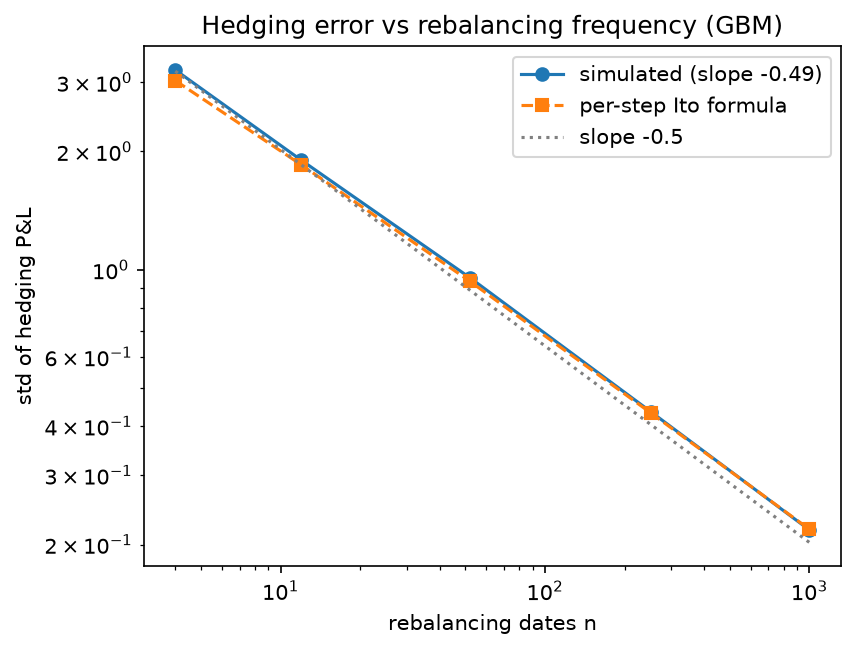

In [4]:
run_experiment("e1_rebalancing")
show_figures("e1_rebalancing")

**Interpretation.** The fitted log-log slope is close to $-1/2$, which ties the simulation to the quadratic-variation argument: the error exists only because $(\Delta W)^2 \ne \Delta t$ at a finite step, and its variance is $2(\Delta t)^2$ per step. The simulated standard deviation follows the per-step Itô formula; the slope over all $n$ is slightly flatter because the formula is a small-$\Delta t$ expansion. To halve the hedging risk one needs four times as many rebalances, which sets up the cost trade-off in E5.

## Step 5: E2, wrong volatility (experiments/e2_wrong_vol.py)

**Concept (the same derivation as Step 2, with $\sigma_h \neq \sigma$).** The stock has true volatility $\sigma$, but the hedger, the **seller** of the call, prices at $\sigma_h$: $X(0) = C(0, S_0)$ with $C$ the BSM price at $\sigma_h$, and holds $\Delta(t) = C_x(t, S(t))$ computed at $\sigma_h$, so $C$ satisfies the BSM equation at $\sigma_h$ while $S$ moves with $\sigma$. The discounted wealth is $d(e^{-rt}X) = C_x\,d(e^{-rt}S)$, and Itô on $e^{-rt}C(t,S(t))$ under the true dynamics gives

$$d\big(e^{-rt}C\big) = e^{-rt}\Big[-rC + C_t + \alpha SC_x + \tfrac12\sigma^2S^2C_{xx}\Big]dt + e^{-rt}\sigma SC_x\,dW.$$

The $dW$ terms cancel in $d\big(e^{-rt}(X - C)\big)$, and using the BSM equation at $\sigma_h$, $rC - C_t - rSC_x = \tfrac12\sigma_h^2S^2C_{xx}$, the $dt$ terms leave

$$d\Big(e^{-rt}\big(X(t) - C(t,S(t))\big)\Big) = \tfrac12\big(\sigma_h^2 - \sigma^2\big)e^{-rt}S(t)^2C_{xx}(t, S(t))\,dt.$$

So the seller's discounted terminal P&L is (El Karoui, Jeanblanc and Shreve, 1998)

$$e^{-rT}\,\text{P\&L} = \tfrac12\big(\sigma_h^2 - \sigma^2\big)\int_0^Te^{-rt}S(t)^2C_{xx}(t, S(t))\,dt,$$

positive when $\sigma_h > \sigma$. **Sign convention:** the hedger is the seller; the option holder has the opposite sign. The code returns the P&L at time $T$, which is $e^{rT}$ times the right-hand side. The integrand $S^2C_{xx}$ is the dollar gamma, always positive for a call, so the sign of the P&L is fixed by the sign of $\sigma_h - \sigma$. Selling too dear ($\sigma_h > \sigma$) locks in a profit; selling too cheap loses. The P&L is random only through the path of the dollar gamma, so it is not riskless even though it has a definite sign.

**Result.** $n = 1000$, 20,000 paths, seed 42, $S_0 = K = 100$, $\alpha = r = 5\%$, $\sigma = 20\%$, $T = 1$:

| sigma_h / sigma | mean sim | mean formula | std error | std sim |
| --- | --- | --- | --- | --- |
| 0.50 | -3.818 | -3.823 | 0.014 | 2.043 |
| 0.75 | -1.947 | -1.949 | 0.006 | 0.893 |
| 1.00 | 0.002 | 0.000 | 0.002 | 0.219 |
| 1.25 | 1.979 | 1.978 | 0.005 | 0.699 |
| 1.50 | 3.967 | 3.966 | 0.009 | 1.208 |

**Interpretation.** Simulated means agree with the formula to within about one standard error everywhere, which checks the sign and size of the result by simulation. The distributions are shifted left or right and are much wider than the correctly specified case, and their spread comes mainly from the dollar-gamma integral varying across paths: paths that end near the strike accumulate more gamma. The pathwise RMSE between simulation and formula (0.17 to 0.33) is the discrete-hedging noise from E1 and is about the same size as the $n = 1000$ std at $\sigma_h = \sigma$ (0.219). Takeaway: a volatility error of 25% costs about 2 on a premium of 10.45, far more than the discretisation error at $n = 1000$.

 sigma_h/sigma  mean_sim  mean_formula  std_error  std_sim  std_formula  pathwise_rmse
        0.5000   -3.8184       -3.8226     0.0144   2.0427       2.0286         0.3282
        0.7500   -1.9465       -1.9492     0.0063   0.8933       0.8644         0.2599
        1.0000    0.0018        0.0000     0.0015   0.2188       0.0000         0.2188
        1.2500    1.9790        1.9775     0.0049   0.6989       0.6626         0.1911
        1.5000    3.9673        3.9657     0.0085   1.2080       1.1849         0.1711


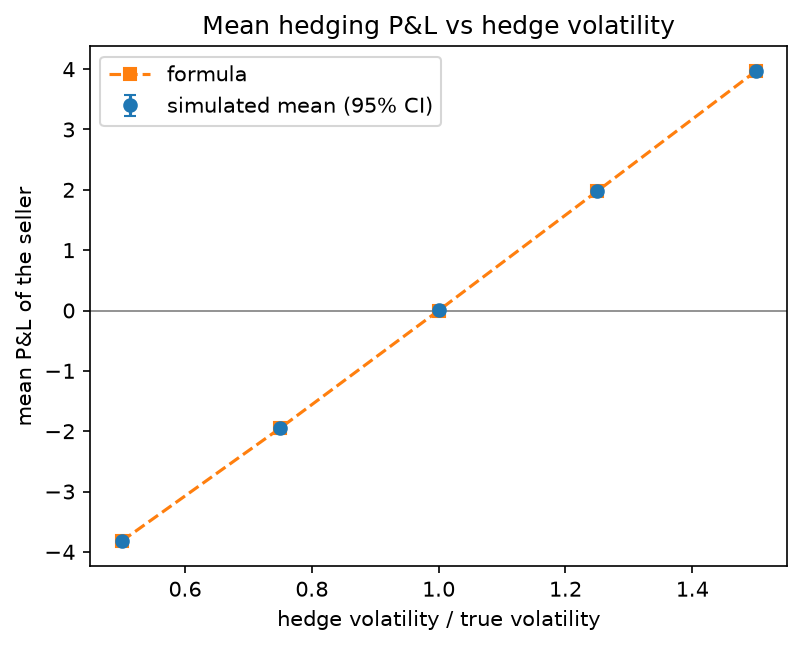

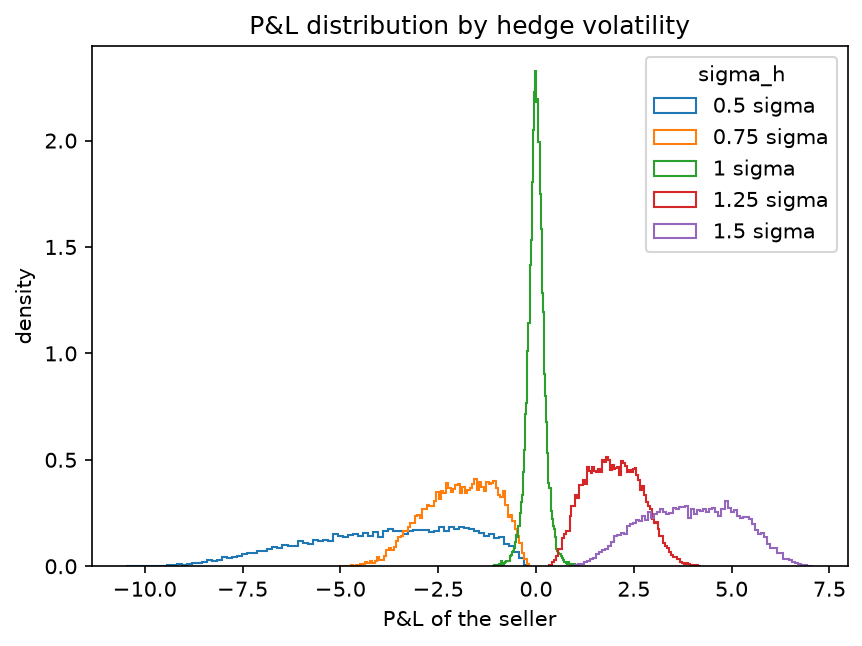

In [5]:
run_experiment("e2_wrong_vol")
show_figures("e2_mean_pnl", "e2_distribution")

**Interpretation.** The simulated mean P&L of the seller agrees with the El Karoui et al. formula at every hedge volatility. Selling and hedging at too high a volatility ($\sigma_h > \sigma$) gives a gain, too low gives a loss, and the distribution is shifted and much wider than in the correctly specified case. A 25% volatility error is worth more than the discretisation error at $n = 1000$.

## Step 6: E3 and E4, wrong dynamics (src/simulators.py, experiments/e3_heston.py, e4_jumps.py)

**Concept: incomplete markets.** BSM works because one traded asset spans the single source of risk $dW$. Under Heston there are two sources of risk ($dW_1$ for the stock, $dW_2$ for the variance) but only the stock is traded, so the variance risk cannot be hedged away. Under jumps the Poisson risk cannot be offset by a continuous Delta hedge, since the stock moves discretely and $\Delta$ cannot adjust in time. In both cases the market is incomplete: the option cannot be replicated, no unique price exists, and a BSM Delta hedge leaves residual risk that does not vanish as rebalancing becomes continuous.

**Heston (E3).** It extends GBM by a stochastic variance $V(t)$ that follows the CIR process of the notes, $dR(t) = (\alpha_R - \beta R(t))\,dt + \sigma_R\sqrt{R(t)}\,dW(t)$, with $E[R(t)] = R(0)e^{-\beta t} + \tfrac{\alpha_R}{\beta}(1 - e^{-\beta t})$ and $\mathrm{Var}(R(t)) \to \alpha_R\sigma_R^2/(2\beta^2)$. To avoid clashing with the stock's $\alpha$ and $\sigma$ the mapping is $R \to V$, $\alpha_R \to a_V$, $\sigma_R \to \xi$ (in the usual Heston notation $a_V = \kappa\theta$, $\beta = \kappa$):

$$dS(t) = \alpha S(t)\,dt + \sqrt{V(t)}\,S(t)\,dW_1(t), \qquad dV(t) = \big(a_V - \beta V(t)\big)dt + \xi\sqrt{V(t)}\,dW_2(t), \qquad dW_1\,dW_2 = \rho\,dt.$$

The variance uses the full-truncation Euler scheme, with $V^+ = \max(V, 0)$ in every coefficient: $V_{i+1} = V_i + (a_V - \beta V_i^+)\Delta t + \xi\sqrt{V_i^+\Delta t}\,Z_2$. The stock then takes the exact lognormal step with the variance frozen at $V_i^+$ (Euler is used only for the variance). The tests check the simulated $E[V(t)]$ and the long-run variance against the two CIR formulas above, and that Heston with $\xi = 0$ reduces to GBM.

**Merton jumps (E4).** The notes only mention that a Poisson process is not a simple process; the model adds compound Poisson jumps to GBM:

$$\frac{dS}{S} = (\alpha - \lambda\bar\kappa)\,dt + \sigma\,dW + (J - 1)\,dN, \qquad \ln J \sim N(m, \delta^2), \quad \bar\kappa = e^{m + \delta^2/2} - 1,$$

with $N$ a Poisson process of rate $\lambda$. It is sampled exactly (a sum of $n$ log-jumps is $N(nm, n\delta^2)$), and the compensator $\lambda\bar\kappa$ keeps $E[S(T)] = S_0e^{\alpha T}$. Tests: Heston and Merton keep $E[S(T)]$; Merton log-variance equals $(\sigma^2 + \lambda(m^2 + \delta^2))T$.

**Setup.** The hedge and premium always use BSM at $\sigma = 20\%$ (the same trader as E1). To make the comparison fair, Heston starts at $V(0) = a_V/\beta = 0.04$ (average variance matches), and Merton's diffusion variance is reduced so that $\sigma_d^2 + \lambda(m^2 + \delta^2) = 0.04$. So differences from GBM are not caused by a higher or lower variance level. Heston paths are simulated with 1,008 Euler steps and the hedge uses every $(1008/n)$-th date, so the simulation error does not change with the hedging frequency. Parameters: $\beta = 2$, $a_V = 0.08$, 20,000 paths, seed 42, $S_0 = K = 100$, $\alpha = r = 5\%$, $T = 1$.

**E3 result (Heston, $n = 252$).** VaR and ES (5% tail losses) are reported in one table of tail statistics. An earlier version simulated Heston on the hedging grid itself. Simulating on the fine grid changed the standard deviations by under 1% (for $\xi = 0.4$, $\rho = -0.7$: 1.960 became 1.952), but small means moved more (0.195 became 0.157; for $\xi = 0.2$ the mean went from $+0.005$ to $-0.018$), which shows part of those small means was Euler path error.

| scenario | mean | std | skew | ex. kurt | VaR | ES |
| --- | --- | --- | --- | --- | --- | --- |
| GBM | 0.002 | 0.432 | -0.15 | 1.92 | 0.70 | 0.99 |
| xi 0.2, rho -0.7 | -0.018 | 1.102 | -0.62 | 1.61 | 1.95 | 2.72 |
| xi 0.4, rho -0.7 | 0.157 | 1.952 | -0.93 | 2.10 | 3.35 | 4.86 |
| xi 0.6, rho -0.7 | 0.453 | 2.647 | -1.28 | 3.24 | 4.46 | 6.70 |
| xi 0.4, rho -0.9 | 0.146 | 1.481 | -0.75 | 0.66 | 2.50 | 3.40 |
| xi 0.4, rho -0.5 | 0.181 | 2.242 | -1.02 | 2.78 | 3.84 | 5.72 |
| xi 0.4, rho 0.0 | 0.300 | 2.549 | -1.09 | 3.71 | 4.24 | 6.44 |
| xi 0.4, rho 0.5 | 0.516 | 2.359 | -0.82 | 2.51 | 3.52 | 5.44 |

Std against $n$ for $\xi = 0.4$, $\rho = -0.7$: $n = 12$: 2.83, 48: 2.17, 252: 1.95, 1008: 1.91 (GBM falls from 1.94 to 0.22). The Heston error flattens at about 1.9 instead of going to 0.

**E3 interpretation.** Std, VaR and ES grow with the vol-of-vol: even $\xi = 0.2$ multiplies the std by about 2.6 relative to GBM. The residual does not vanish with $n$, as the incomplete-market argument predicts. The error comes from the fact that the BSM Delta and gamma use a constant 20% while the true instantaneous volatility is $\sqrt{V(t)}$, so the seller is effectively in the wrong-volatility situation of E2 with a randomly varying volatility (E2 gives P&L $= \tfrac12(\sigma_h^2 - V(t))S^2C_{xx}\,dt$ integrated over time). The left skew deepens with $\xi$. The mean is about zero at $\xi = 0.2$ and positive at $\xi = 0.4$ and $0.6$ (0.16 and 0.45). A pricing bias is one possible reason: the premium was computed at constant 20%, and the Heston at-the-money call may be worth less because the at-the-money price is concave in variance (Jensen), so the seller has been paid too much. I have not isolated this, and the means are sensitive to the Euler grid, as noted above. Correlation changes the shape: $\rho = -0.9$ gives the smallest std of the $\xi = 0.4$ runs (1.48), and the largest std is at $\rho = 0$ (2.55). Strong correlation makes the variance shocks mostly a function of the stock shocks, so the Delta hedge captures part of them; at $\rho = 0$ the variance risk is orthogonal to the stock and entirely unhedgeable.

**E4 result (Merton, $n = 252$, jump std 0.1, variance-matched).**

| scenario | mean | std | skew | ex. kurt | VaR | ES |
| --- | --- | --- | --- | --- | --- | --- |
| GBM | 0.002 | 0.432 | -0.15 | 1.92 | 0.70 | 0.99 |
| lam 0.25, m -0.1 | 0.062 | 1.523 | -4.31 | 25.81 | 2.67 | 5.39 |
| lam 0.5, m -0.1 | 0.106 | 2.183 | -3.29 | 15.31 | 4.39 | 7.38 |
| lam 1.0, m -0.1 | 0.184 | 3.053 | -2.04 | 5.37 | 6.28 | 9.16 |
| lam 0.5, m -0.05 | 0.058 | 1.559 | -3.93 | 24.41 | 2.89 | 5.30 |
| lam 0.5, m -0.2 | 0.272 | 4.279 | -1.93 | 4.00 | 9.17 | 12.54 |

Std against $n$ for $\lambda = 0.5$, $m = -0.1$: $n = 12$: 2.78, 52: 2.30, 252: 2.18, 1000: 2.18 (GBM 1.94 to 0.22).

**E4 interpretation.** The seller is short gamma, so a large move in either direction loses money: a jump of size $J$ costs roughly $\tfrac12C_{xx}S^2(J-1)^2$ plus the first-order mismatch, and the Delta cannot be adjusted in time. The distribution has a peak at small positive P&L (paths with no jump, where diffusion volatility is below 20% and the seller collects the excess premium) and a long left tail (paths with jumps). Hence the very large negative skew and kurtosis, and the ES much larger than VaR. Rarer jumps (small $\lambda$) give the heaviest tails in skew and kurtosis terms (kurtosis 25.8 at $\lambda = 0.25$), while more frequent jumps give larger variance and larger VaR and ES. The std flattens at about 2.18 as $n$ grows, so more frequent hedging cannot remove jump risk. Larger jumps make everything worse: at $m = -0.2$ the VaR is 9.17.

**Caveat.** Variance matching is my design choice, not a calibration. I chose parameters for illustration (not fitted to market data), so the numbers show direction and rough size, not market values.

**Monte Carlo error.** With 20,000 paths, bootstrap standard errors over the paths (`bootstrap_standard_errors`, 500 resamples) are, at $n = 252$:

| scenario | mean | std | skew | ex. kurt | ES |
| --- | --- | --- | --- | --- | --- |
| GBM | 0.0028 | 0.0031 | 0.046 | 0.24 | 0.013 |
| Heston $\xi = 0.4$, $\rho = -0.7$ | 0.014 | 0.014 | 0.039 | 0.24 | 0.066 |
| Merton $\lambda = 0.5$, $m = -0.1$ | 0.015 | 0.031 | 0.093 | 1.26 | 0.127 |

The standard deviation is accurate to about 0.7% (Heston $1.95 \pm 0.014$) and the ES to 1 to 2% ($4.86 \pm 0.066$), but the skewness is only good to $\pm 0.04$ to $\pm 0.09$ and the excess kurtosis to $\pm 0.24$ (Heston) or $\pm 1.3$ (Merton). Small differences in skewness or kurtosis between scenarios are therefore not interpreted.

n = 252, 20000 paths
                    mean    std    skew  excess_kurtosis  VaR_5   ES_5
scenario                                                              
GBM               0.0018 0.4317 -0.1526           1.9218 0.6995 0.9872
xi=0.2, rho=-0.7 -0.0179 1.1019 -0.6238           1.6063 1.9511 2.7169
xi=0.4, rho=-0.7  0.1566 1.9517 -0.9280           2.1037 3.3494 4.8572
xi=0.6, rho=-0.7  0.4525 2.6473 -1.2752           3.2361 4.4614 6.6951
xi=0.4, rho=-0.9  0.1458 1.4810 -0.7491           0.6608 2.4959 3.4040
xi=0.4, rho=-0.5  0.1813 2.2415 -1.0242           2.7782 3.8367 5.7153
xi=0.4, rho=0.0   0.2996 2.5489 -1.0904           3.7060 4.2372 6.4429
xi=0.4, rho=0.5   0.5164 2.3591 -0.8230           2.5069 3.5230 5.4395


Monte Carlo standard errors with 20000 paths (bootstrap over the paths)
                   mean    std   skew  excess_kurtosis   ES_5
GBM              0.0028 0.0031 0.0464           0.2427 0.0133
xi=0.4, rho=-0.7 0.0140 0.0138 0.0387           0.2389 0.0656


   N  gbm_std  heston_std
  12   1.9419      2.8272
  48   0.9845      2.1682
 252   0.4317      1.9517
1008   0.2198      1.9113


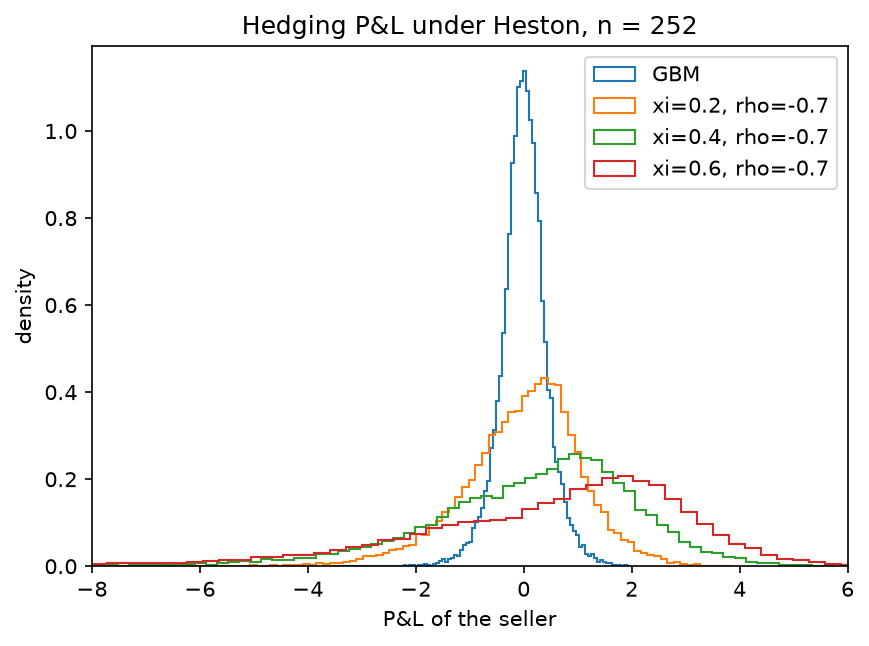

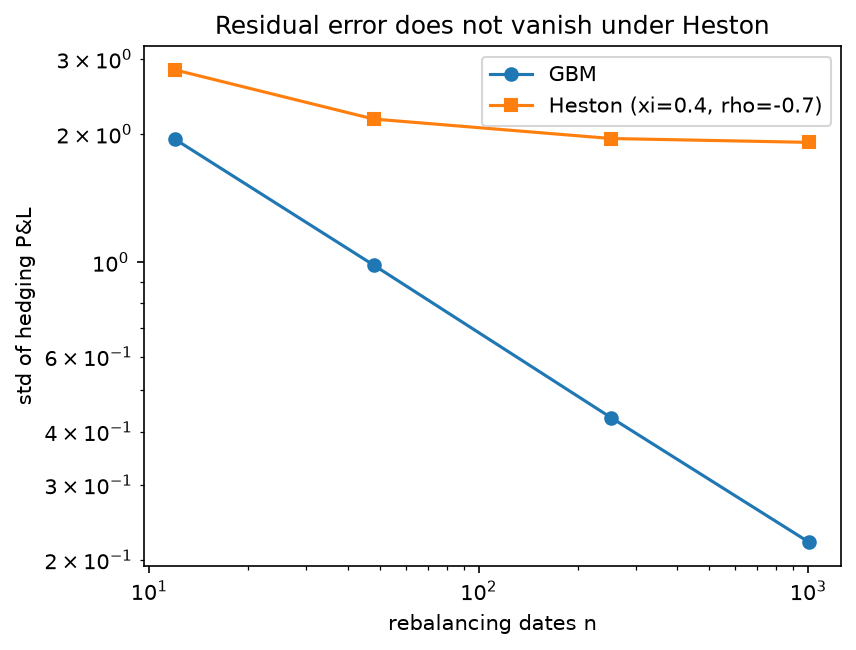

In [6]:
run_experiment("e3_heston")
show_figures("e3_distribution", "e3_std_vs_n")

**Interpretation (E3).** Standard deviation, VaR and ES all grow with the vol-of-vol, and the error does not shrink to zero as $n$ grows: the market is incomplete, so BSM Delta hedging leaves residual risk. Correlation changes the size of the residual (strong negative correlation lets the stock hedge part of the variance risk). The positive mean is consistent with a premium priced at constant volatility being too high, which I did not isolate separately.

## E4: Merton jumps

n = 252, 20000 paths, jump std = 0.1
                   mean    std    skew  excess_kurtosis  VaR_5    ES_5
scenario                                                              
GBM              0.0018 0.4317 -0.1526           1.9218 0.6995  0.9872
lam=0.25, m=-0.1 0.0615 1.5225 -4.3081          25.8100 2.6694  5.3894
lam=0.5, m=-0.1  0.1061 2.1825 -3.2859          15.3114 4.3897  7.3775
lam=1.0, m=-0.1  0.1838 3.0525 -2.0401           5.3678 6.2815  9.1644
lam=0.5, m=-0.05 0.0578 1.5586 -3.9300          24.4072 2.8882  5.2968
lam=0.5, m=-0.2  0.2723 4.2789 -1.9250           4.0002 9.1739 12.5356


Monte Carlo standard errors with 20000 paths (bootstrap over the paths)
                  mean    std   skew  excess_kurtosis   ES_5
GBM             0.0028 0.0031 0.0464           0.2427 0.0133
lam=0.5, m=-0.1 0.0148 0.0314 0.0933           1.2611 0.1272


   N  gbm_std  merton_std
  12   1.9419      2.7762
  52   0.9523      2.2956
 252   0.4317      2.1825
1000   0.2188      2.1750


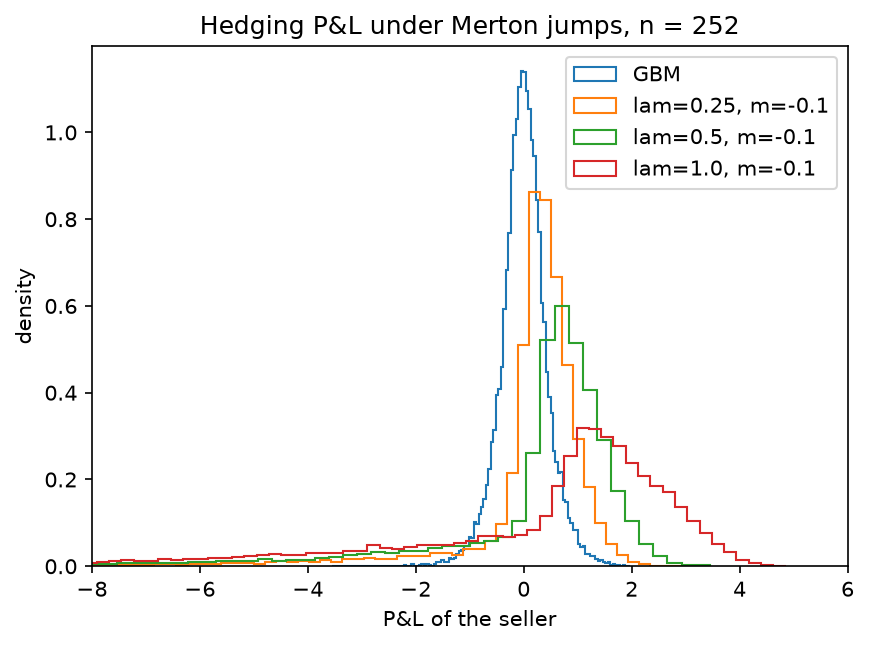

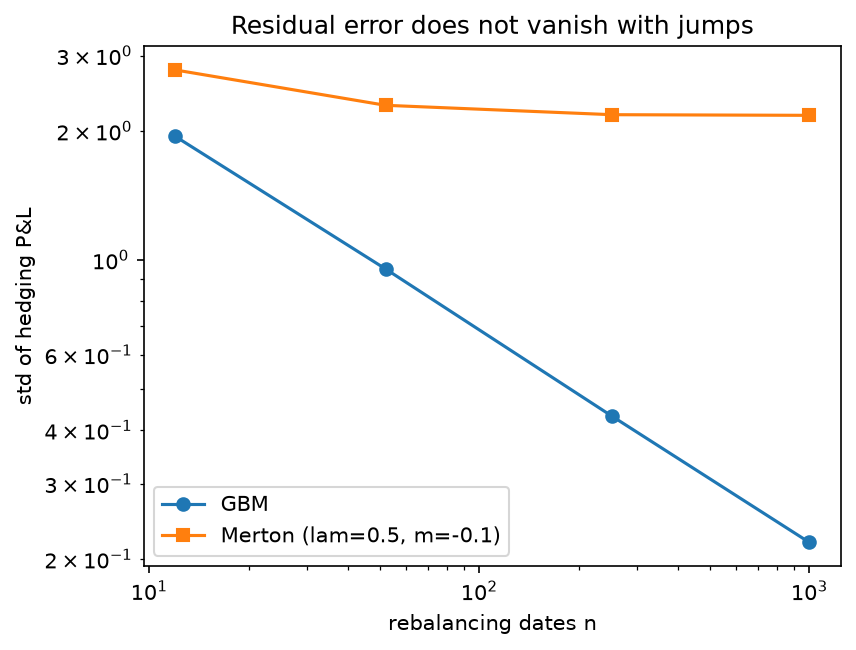

In [7]:
run_experiment("e4_jumps")
show_figures("e4_distribution", "e4_std_vs_n")

**Interpretation (E4).** The seller is short gamma, so large moves in either direction lose money. Most paths have no jump and a small gain, a few have a large loss, giving a long left tail, very negative skew, high kurtosis, and an ES far above the VaR. The error again levels off as $n$ grows. The comparison is variance-matched, so these differences come from the shape of the distribution, not its variance. Parameters are illustrative, not calibrated.

## Step 7: E5, transaction costs (src/costs.py, experiments/e5_costs.py)

**Leland (1985).** It extends the BSM hedging argument of Step 2 (hold $\Delta(t) = C_x$ and rebalance) by a cost on every trade; the Step 4 error formula supplies the trade sizes.

**Concept: cost versus risk.** With proportional costs the seller pays a fraction of every trade, so hedging more often reduces discretisation risk (E1: std $\sim n^{-1/2}$) but raises costs. Per step the hedge ratio changes by about $C_{xx}\,dS$, and $dS \sim S\sigma\sqrt{\Delta t}\,Z$, so the shares traded have mean absolute size $C_{xx}S\sigma\sqrt{\Delta t}\,E|Z| = C_{xx}S\sigma\sqrt{\Delta t}\sqrt{2/\pi}$. With one-way cost $\tfrac{k}{2}S$ per share ($k$ is Leland's round-trip rate):

$$\text{cost per step} \sim \tfrac{k}{2}\sqrt{\tfrac2\pi}\,\sigma\sqrt{\Delta t}\,C_{xx}S^2, \qquad \text{total expected cost} \sim \tfrac{k}{2}\sqrt{\tfrac2\pi}\,\frac{\sigma}{\sqrt{\Delta t}}\int_0^TS^2C_{xx}\,dt.$$

So the cost grows like $1/\sqrt{\Delta t} = \sqrt n$, while the hedging risk falls like $1/\sqrt n$. There must be an interior optimum.

**Leland's adjusted volatility.** The extra cost acts like an extra gamma term in the E2 formula, $\tfrac12(\hat\sigma^2 - \sigma^2)\int S^2C_{xx}\,dt$, with

$$\hat\sigma^2 = \sigma^2\Big(1 + \sqrt{\tfrac2\pi}\,\frac{k}{\sigma\sqrt{\Delta t}}\Big),$$

so pricing and hedging at $\hat\sigma$ covers the expected cost. The correction is of order $k/\sqrt{\Delta t}$, not of order $k$, which is why frequent trading is so expensive. The code charges $\tfrac{k}{2}|\text{shares traded}|\,S$ per trade, so $k$ is the round-trip rate, as in Leland. The initial purchase pays the cost too; the final delivery of shares does not.

**Optimal $n$.** I measure risk with the RMSE of the net P&L about zero, $\sqrt{\text{bias}^2 + \text{variance}}$. The bias is the expected cost. With std $\sim s/\sqrt n$ and cost $\sim a\sqrt n$ ($a$ proportional to $k$):

$$\text{RMSE}^2 = a^2n + \frac{s^2}{n}, \quad \text{minimised at } n^* = \frac{s}{a} \;\;(\text{so } n^* \text{ falls roughly like } 1/k).$$

The choice of RMSE is mine. Other criteria (a mean-variance objective with another risk aversion, or ES) give a different $n^*$, so "optimal" here means optimal for this criterion.

**Result.** GBM, $S_0 = K = 100$, $\alpha = r = 5\%$, $\sigma = 20\%$, 20,000 paths, seed 42.

Cost against the Leland formula (selected rows):

| k | n | mean cost | Leland cost | std P&L |
| --- | --- | --- | --- | --- |
| 0.005 | 52 | 0.710 | 0.705 | 1.001 |
| 0.005 | 252 | 1.373 | 1.370 | 0.656 |
| 0.005 | 1000 | 2.580 | 2.578 | 0.979 |
| 0.01 | 252 | 2.746 | 2.739 | 1.062 |

The simulated cost matches the formula to within 2% in every row (best 0.1% at $n = 1000$), and grows by about 1.9 for each 4x in $n$ ($\sqrt4 = 2$ asymptotically, a bit less because the initial purchase is constant). The std of net P&L stops falling at large $n$, because the random cost adds variance: at $k = 0.005$ it is 1.00 at $n = 52$, 0.66 at $n = 252$ and 0.98 at $n = 1000$, against 0.22 at $n = 1000$ with no costs.

Optimal $n$ (searched over the grid $n = 12, 26, 52, 78, 104, 156, 208, 252, 378, 504, 756, 1000$):

| k | n* simulated | n* closed form s/a | min RMSE | Leland correction at n* |
| --- | --- | --- | --- | --- |
| 0.001 | 378 | 398 | 0.509 | 0.078 |
| 0.0025 | 156 | 159 | 0.834 | 0.125 |
| 0.005 | 78 | 80 | 1.205 | 0.176 |
| 0.01 | 26 | 40 | 1.801 | 0.203 |

The closed form agrees with the simulation to a few percent for $k$ up to 0.005. At $k = 0.01$ the simulated optimum (26) is on a flat RMSE curve between $n = 26$ and 52 (1.80 and 1.83), and the grid is coarse, so the gap to 40 is within the resolution. The closed-form $n^*$ has log-log slope exactly $-1$ in $k$, which is built in by the cost being proportional to $k$. The simulated optima (378, 156, 78, 26) fall only roughly like $1/k$, and only for small $k$: from $k = 0.005$ to $0.01$ the simulated $n^*$ falls by a factor of 3, not 2, because the grid is coarse and the RMSE is flat near the minimum there.

Leland check at $k = 0.005$ (premium and Deltas both at $\sigma$ or at $\hat\sigma$):

| n | sigma hat | mean P&L at sigma | mean P&L at sigma hat | std at sigma | std at sigma hat |
| --- | --- | --- | --- | --- | --- |
| 26 | 0.2099 | -0.563 | -0.162 | 1.361 | 1.356 |
| 52 | 0.2139 | -0.734 | -0.164 | 1.001 | 0.981 |
| 252 | 0.2295 | -1.410 | -0.163 | 0.656 | 0.460 |

**Interpretation.** Pricing at $\hat\sigma$ removes the $n$-dependent cost bias: the mean P&L goes from $-0.56$, $-0.73$, $-1.41$ to a constant $-0.16$ for all three $n$. The remaining $-0.16$ is the initial purchase cost, $\tfrac{k}{2}\Delta(0)S_0 = 0.0025 \times 0.64 \times 100 = 0.16$, which Leland's formula does not include (it covers the rebalancing). So the Leland scaling is confirmed for the cost bias. Note that Leland's $\hat\sigma$ is not the optimal-$n$ criterion: Leland's $\sqrt{2/\pi}\,k/(\sigma\sqrt{\Delta t})$ is about 0.08 to 0.20 at the optimum, so the optimal frequency is where the correction is a moderate share of the volatility, not where it equals it. Practical meaning: with $k = 0.5\%$ (round trip), weekly to daily hedging ($n = 52$ to 252) is already too frequent; the best is about $n = 78$ under this RMSE criterion.

     k    N  mean_cost  leland_cost  mean_pnl  std_pnl   rmse  pred_rmse
0.0010   12     0.0819       0.0804   -0.0893   1.9471 1.9491     1.8485
0.0025   12     0.2049       0.2010   -0.2165   1.9552 1.9671     1.8576
0.0050   12     0.4097       0.4020   -0.4286   1.9693 2.0154     1.8900
0.0100   12     0.8195       0.8039   -0.8528   2.0002 2.1744     2.0141
0.0010   52     0.1421       0.1410   -0.1484   0.9585 0.9699     0.9468
0.0025   52     0.3552       0.3525   -0.3681   0.9712 1.0386     1.0004
0.0050   52     0.7104       0.7051   -0.7343   1.0007 1.2412     1.1720
0.0100   52     1.4209       1.4102   -1.4667   1.0879 1.8261     1.6926
0.0010  252     0.2746       0.2739   -0.2805   0.4460 0.5269     0.5119
0.0025  252     0.6864       0.6848   -0.7040   0.5017 0.8645     0.8099
0.0050  252     1.3729       1.3696   -1.4098   0.6560 1.5550     1.4363
0.0100  252     2.7458       2.7392   -2.8215   1.0618 3.0147     2.7731
0.0010 1000     0.5159       0.5156   -0.5280   0.2

Leland check, k = 0.005
  N premium_and_hedge_vol    vol  mean_pnl  std_pnl
 26                 sigma 0.2000   -0.5633   1.3614
 26             sigma_hat 0.2099   -0.1615   1.3558
 52                 sigma 0.2000   -0.7343   1.0007
 52             sigma_hat 0.2139   -0.1638   0.9805
252                 sigma 0.2000   -1.4098   0.6560
252             sigma_hat 0.2295   -0.1634   0.4597


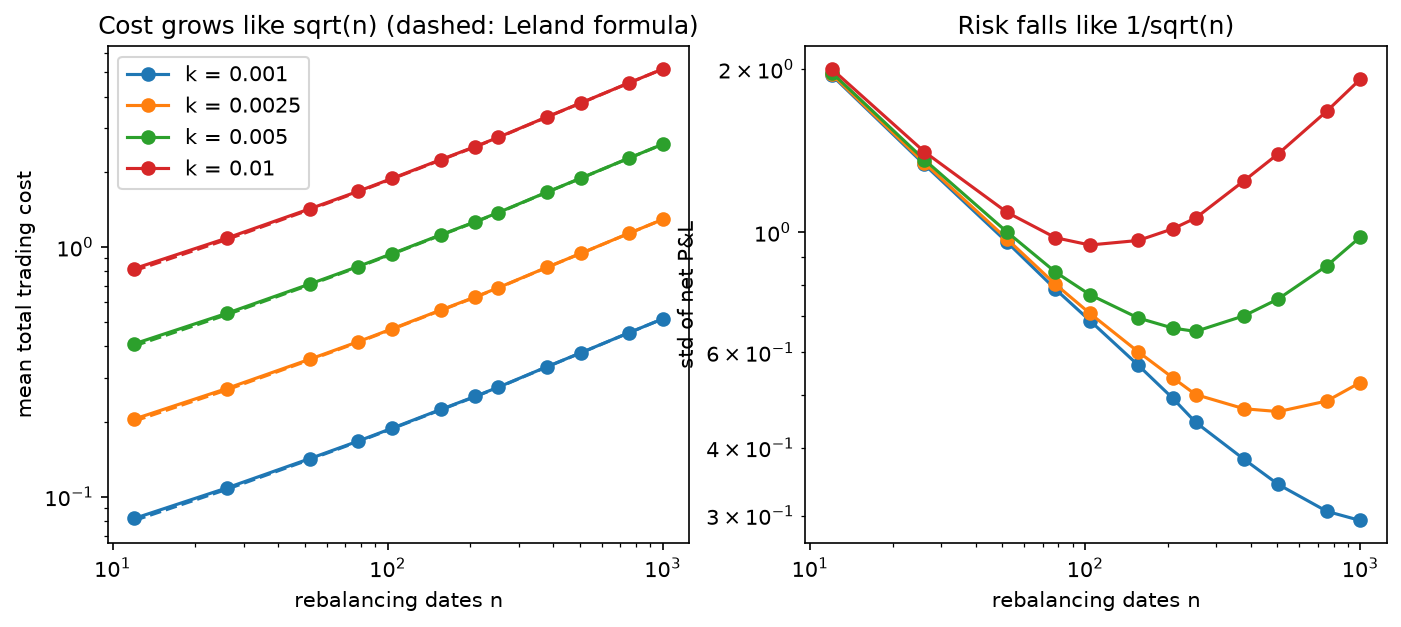

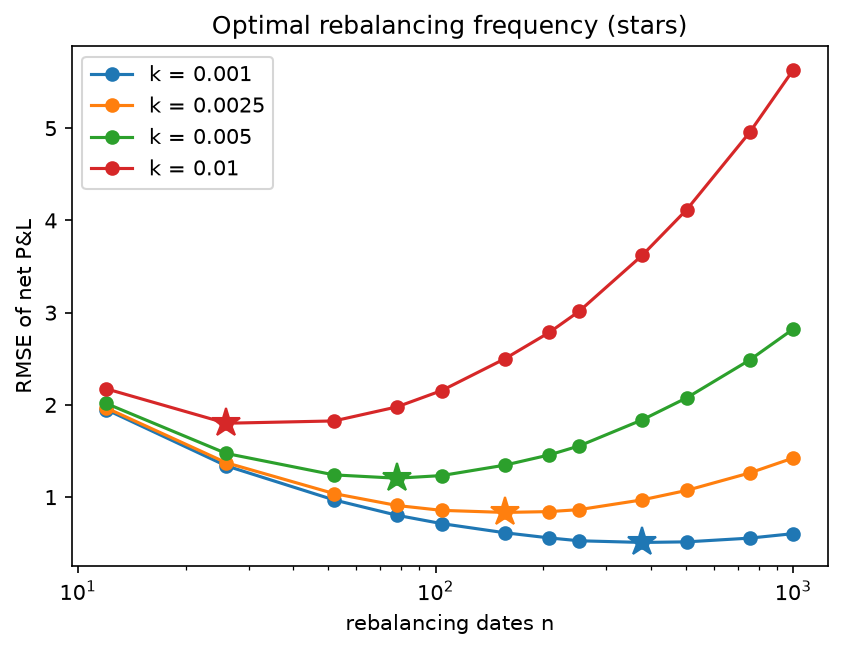

In [8]:
run_experiment("e5_costs")
show_figures("e5_cost_and_risk", "e5_optimal_n")

**Interpretation.** The simulated total cost matches Leland's expected-cost formula, cost grows like $\sqrt n$ while risk falls like $1/\sqrt n$, and the RMSE has an interior minimum (stars). The optimal $n$ falls as $k$ rises, roughly like $1/k$ for small $k$ (the closed form $n^* = s/a$ is close, but from $k = 0.005$ to $0.01$ the simulated $n^*$ falls by a factor of 3, not 2, because the grid is coarse). Pricing and hedging at $\hat\sigma_L$ removes the $n$-dependent cost bias; the remaining $-0.16$ is the initial purchase cost, which Leland's formula does not include. The optimum depends on the RMSE criterion chosen.

## Step 8: E6, moneyness and maturity (experiments/e6_moneyness_maturity.py)

**Concept.** The per-step error $\tfrac12C_{xx}\sigma^2S^2\big[(\Delta W)^2 - \Delta t\big]$ is proportional to the dollar gamma $S^2C_{xx}$ along the path, so the hedging error is large where and when the option has high gamma: close to the strike, and close to expiry. From Step 4 the variance of the total error is a sum over steps of $\tfrac12(\Delta t)^2(\sigma^2S^2C_{xx})^2$ (compounded to $T$), now split by step in `error_variance_profile`. For an at-the-money option, $C_{xx}S^2$ grows like $1/\sqrt\tau$ as $\tau = T - t \to 0$, so late steps contribute most. A deep in- or out-of-the-money option has small gamma, and so a small error in absolute terms.

**Setup.** Weekly hedging ($\Delta t = 1/52$, so $n = 52T$), GBM with $S_0 = 100$, $\alpha = r = 5\%$, $\sigma = 20\%$, 20,000 paths, seed 42.

**Result: strike sweep ($T = 1$, $n = 52$).**

| K | premium | S^2 C_xx at t = 0 | std sim | std Ito formula | std / premium |
| --- | --- | --- | --- | --- | --- |
| 80 | 24.59 | 68.1 | 0.465 | 0.450 | 0.019 |
| 90 | 16.70 | 135.8 | 0.745 | 0.729 | 0.045 |
| 100 | 10.45 | 187.6 | 0.952 | 0.936 | 0.091 |
| 110 | 6.04 | 197.9 | 1.017 | 0.995 | 0.168 |
| 120 | 3.25 | 170.4 | 0.955 | 0.934 | 0.294 |

**Result: maturity sweep ($K = 100$, weekly hedging).**

| T | n | premium | S^2 C_xx at t = 0 | std sim | std Ito formula | std / premium |
| --- | --- | --- | --- | --- | --- | --- |
| 0.1 | 5 | 2.77 | 626.9 | 0.937 | 0.875 | 0.338 |
| 0.25 | 13 | 4.62 | 392.9 | 0.944 | 0.896 | 0.205 |
| 0.5 | 26 | 6.89 | 273.6 | 0.943 | 0.917 | 0.137 |
| 1.0 | 52 | 10.45 | 187.6 | 0.952 | 0.936 | 0.091 |
| 2.0 | 104 | 16.13 | 124.8 | 0.952 | 0.938 | 0.059 |

For $K = 100$, $T = 1$, the last weekly step alone carries about 7% of the total error variance, and the first step about 1.3% (third panel of the figure; $K = 80$ and 120 look similar, with the final step at 8.5% and 7.5%).

**Interpretation.**
- Against strike, the std rises from 0.47 ($K = 80$) to a peak of 1.02 near $K = 110$ and falls again. This follows the gamma profile: the dollar gamma at $t = 0$ peaks near $K = 110$ for $T = 1$, and the std peaks at the same strike. The $t = 0$ gamma is only a rough guide ($K = 80$ has a higher std than its $t = 0$ gamma suggests) because the error accumulates over the whole path, and the stock can drift toward the strike. The Itô formula follows the simulation at all strikes, about 2 to 3% below it. The remaining gap is the higher-order terms that the second-order formula leaves out.
- The absolute error does not tell the whole story: relative to the premium, the error grows steadily with the strike, from 2% at $K = 80$ to 29% at $K = 120$. Out-of-the-money options are cheap and their small errors are large relative to what was paid.
- Against maturity at fixed weekly $\Delta t$, the std is nearly flat (0.94 to 0.95 from $T = 0.1$ to 2). I checked this only numerically, and the following explanation is my own reasoning, not tested separately: with dollar gamma proportional to $1/\sqrt\tau$, each step has variance of order $(\Delta t)^2/\tau_i$, and the sum over $i$ is of order $\Delta t\log n$, so the std depends on $T$ only slowly through $\log n$. The Itô formula understates the simulated std at short maturities (7% below at $T = 0.1$, where $n = 5$ steps are too coarse for the second-order expansion), which is consistent with the small-$\Delta t$ nature of the formula noted in E1.
- Relative to the premium, short-dated options are much harder to hedge weekly: 34% at $T = 0.1$ against 6% at $T = 2$.

Strike sweep, T = 1, weekly hedging
       K      T  N  premium  dollar_gamma_0  std_sim  std_pred  std_over_premium
 80.0000 1.0000 52  24.5888         68.1360   0.4650    0.4495            0.0189
 90.0000 1.0000 52  16.6994        135.8129   0.7454    0.7285            0.0446
100.0000 1.0000 52  10.4506        187.6202   0.9523    0.9362            0.0911
110.0000 1.0000 52   6.0401        197.8802   1.0173    0.9949            0.1684
120.0000 1.0000 52   3.2475        170.3692   0.9547    0.9335            0.2940
Maturity sweep, K = 100, weekly hedging
       K      T   N  premium  dollar_gamma_0  std_sim  std_pred  std_over_premium
100.0000 0.1000   5   2.7737        626.9314   0.9372    0.8745            0.3379
100.0000 0.2500  13   4.6150        392.8800   0.9442    0.8956            0.2046
100.0000 0.5000  26   6.8887        273.5866   0.9430    0.9173            0.1369
100.0000 1.0000  52  10.4506        187.6202   0.9523    0.9362            0.0911
100.0000 2.0000 104  16.1268

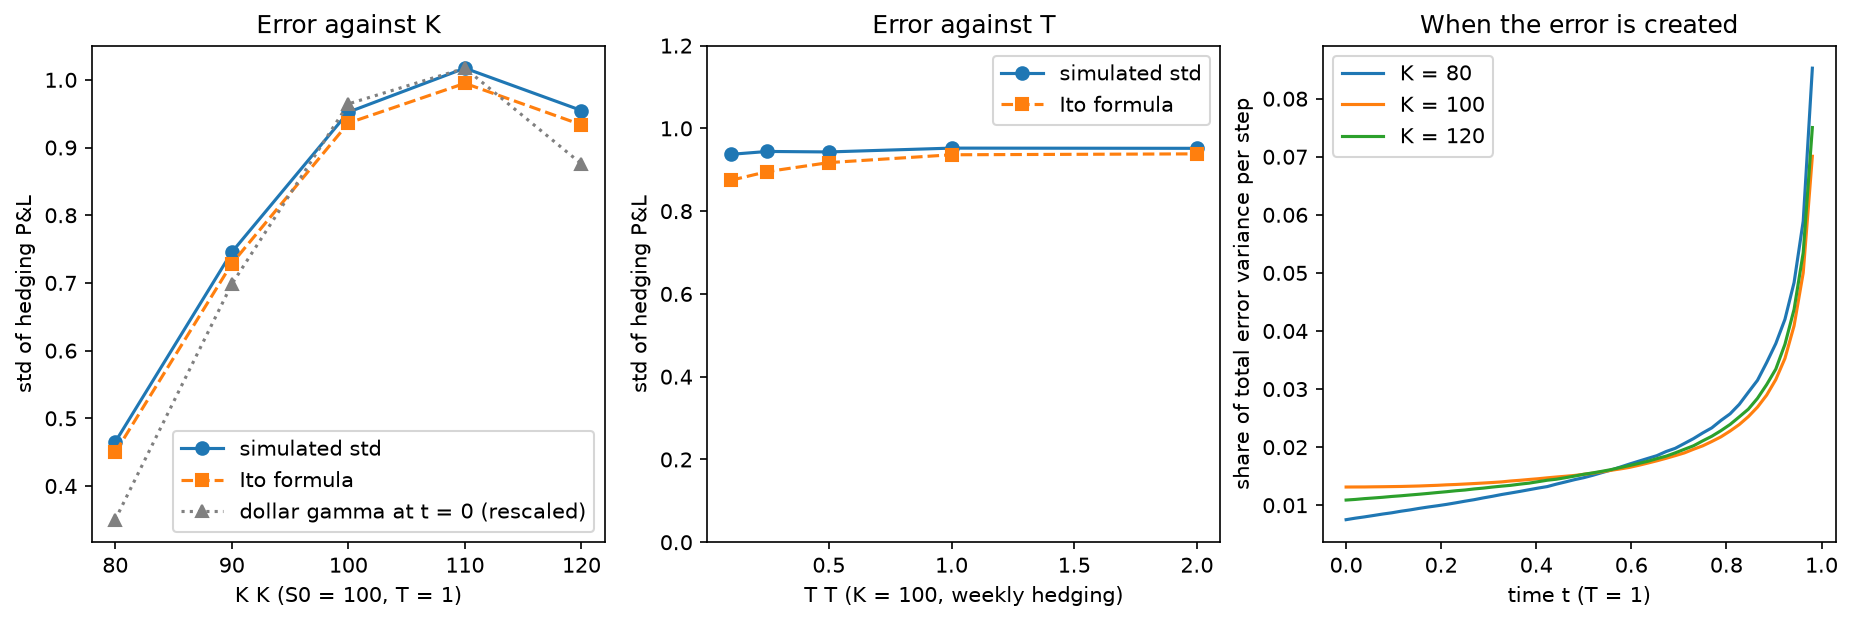

In [9]:
run_experiment("e6_moneyness_maturity")
show_figures("e6_moneyness_maturity")

**Interpretation.** The error follows the dollar-gamma profile $S^2C_{xx}$: it is largest for strikes near the money and is created mostly near expiry (right panel). Relative to the premium, out-of-the-money and short-dated options are much harder to hedge. The Itô formula tracks the simulation at all strikes, slightly low because it drops higher-order terms.

## Step 9: E7, backtest on real listed option prices (src/backtest.py, experiments/e7_backtest.py)

**Concept.** The simulations assume a model for the stock. The backtest asks how a BSM Delta hedge, $\Delta(t_i) = C_x$, performs on the real NIFTY path when the option sold is a real listed contract, so that both the stock path and the option price come from the market. The theory it tests is the one already derived: the hedging error is the discretisation error of E1 plus the wrong-volatility term of E2, where the "true" volatility is whatever NIFTY realised over the option's life.

**Realised and implied volatility (which is used where).** The realised volatility is the notes' formula, computed from the stock path over the option's life $[T_1, T_2]$,

$$\hat\sigma = \sqrt{\frac{1}{T_2 - T_1}\sum_{i=0}^{n-1}\Big[\ln\frac{S(t_{i+1})}{S(t_i)}\Big]^2},$$

which estimates $\sigma$ because $\sum(\Delta W(t_i))^2 \to T_2 - T_1$ (quadratic variation). The implied volatility is the $\sigma$ for which $\text{BSM}(\tau, x, K, r, \sigma)$ equals the listed market price. The listed call is priced and hedged at its **implied** volatility ($\sigma_h$ in E2); the **realised** volatility plays the role of the true $\sigma$ in the E2 formula.

**Data (see data/SOURCE.md).** Listed prices: NSE F&O bhavcopy, one file per trading day from 2 January 2015 to 11 November 2026 (2,920 days; the older bhavcopy format up to 5 July 2024, the UDiFF format from 8 July 2024), downloaded on 15 November 2026. Index path and India VIX: Yahoo Finance via yfinance (^NSEI, ^INDIAVIX), same date.

**Method.** An entry date is used when a NIFTY expiry falls exactly 20 trading days later ($T = 20/252$ years, about 28 calendar days), which gives the same 20-step uniform grid as the simulations. Before 2019 NIFTY had monthly expiries only (about one window a month, not overlapping); weekly expiries start in 2019 (about one window a week, overlapping). The traded call with the strike closest to the NIFTY close is sold at its listed close `ClsPric`. Its own implied volatility ($r = 6\%$, no dividends) is used for the Deltas, so the engine's premium equals the market price. The hedge is rebalanced daily (20 steps) or weekly (4 steps) along the real NIFTY path, and the call is settled at the NIFTY close on the expiry date. P&L is divided by the premium. The simulations use $S_0 = K = 100$, $\alpha = r = 6\%$, $T = 20/252$ and $\sigma = 14.77\%$, the sample's mean implied volatility, with the premium and Deltas at that $\sigma$ and 20 daily steps (weekly hedging takes every fifth date). Heston ($\beta = 2$, $a_V = \beta\sigma^2$, $V(0) = \sigma^2$, $\xi = 0.4$, $\rho = -0.7$) uses the E3 settings, not the $\sigma = 20\%$, $T = 1$ of that experiment. Merton is not simulated for the 20-day window: the E4 jump parameters were chosen for one-year options, and in a 20-day window almost every path has no jump while a few lose far more than the premium (an earlier run gave skewness $-8$ and excess kurtosis 84), which says nothing about NIFTY. A single $\sigma$ is a simplification, since the real windows run from calm periods to the 2020 crash. Dividing by the premium (roughly proportional to $\sigma$ for an at-the-money option) puts the windows on one scale, and the residual comparison below removes the main regime effect.

**Data-quality filter (important).** The older files have no underlying price and I keep only calls that traded that day, so on days when no near-the-money call traded, the nearest traded strike can be far from the money. A first run without a filter had 23 of 395 windows with a strike more than 1% from spot (one 44% away, 20 March 2020). These are not at-the-money options, and they distorted the result (skewness $+0.71$ and excess kurtosis 9.4, against $-1.10$ and 2.5 without them). I now require $|K/S - 1| \le 1\%$, which leaves 372 windows. The 1% tolerance is my choice, so the sensitivity is reported below. I found the problem from the 44% gap, not by searching for nicer numbers.

**The VIX baseline.** To check how well a model-priced option reproduces the listed results (it extends the same BSM pricing of Step 2), the same hedge is run on a synthetic at-the-money call priced with Black-Scholes at India VIX$/100$ on the entry date. It needs no option data, so it covers every trading day (2,884 windows, January 2015 to October 2026, windows without a VIX value dropped), and it is also reported on exactly the dates of the listed windows.

**Result.** 372 listed windows, 28 January 2015 to 9 October 2026; strikes within 0.98% of spot (median 0.09%); median premium 353 index points. P&L / premium (VaR and ES are 5% losses):

| sample | mean | std | skew | ex. kurt | VaR 5% | ES 5% |
| --- | --- | --- | --- | --- | --- | --- |
| listed daily | 0.058 | 0.247 | -1.10 | 2.46 | 0.449 | 0.625 |
| listed weekly | 0.008 | 0.398 | -1.57 | 5.83 | 0.640 | 1.099 |
| VIX baseline daily, same dates | 0.111 | 0.231 | -1.81 | 6.78 | 0.232 | 0.570 |
| VIX baseline weekly, same dates | 0.069 | 0.372 | -1.61 | 6.26 | 0.506 | 0.930 |
| VIX baseline daily, all days | 0.127 | 0.228 | -1.63 | 5.85 | 0.234 | 0.542 |
| VIX baseline weekly, all days | 0.089 | 0.372 | -1.58 | 6.75 | 0.524 | 0.923 |
| GBM daily | 0.001 | 0.167 | -0.37 | 1.71 | 0.277 | 0.392 |
| GBM weekly | -0.001 | 0.352 | -0.59 | 1.28 | 0.603 | 0.850 |
| Heston daily | 0.007 | 0.226 | -0.84 | 2.77 | 0.379 | 0.572 |
| Heston weekly | 0.004 | 0.387 | -1.03 | 2.84 | 0.684 | 1.008 |

Mean implied volatility of the listed calls 14.77%, mean realised volatility $\hat\sigma$ 13.50%; implied above realised in 68.3% of windows. The E2 formula applied window by window ($\hat\sigma$ as the true $\sigma$, the listed implied volatility as $\sigma_h$): mean 23.0 index points against 23.6 in the backtest, correlation 0.868 across windows. Sensitivity to the at-the-money tolerance (daily hedging):

| max strike gap | windows | mean | std | skew | ex. kurt |
| --- | --- | --- | --- | --- | --- |
| 0.5% | 356 | 0.060 | 0.242 | -1.07 | 2.46 |
| 1% | 372 | 0.058 | 0.247 | -1.10 | 2.46 |
| 2% | 376 | 0.058 | 0.247 | -1.09 | 2.40 |

Mean P&L / premium by entry year (windows in brackets): 2015 0.041 (12), 2016 -0.004 (12), 2017 0.024 (12), 2018 -0.057 (11), 2019 0.069 (17), 2020 0.022 (20), 2021 -0.014 (39), 2022 0.040 (52), 2023 0.125 (51), 2024 0.054 (52), 2025 0.152 (53), 2026 0.026 (41).

**Statistical uncertainty (moving-block bootstrap).** Windows that start on nearby dates overlap in time, so I resample blocks of 5 consecutive windows (2,000 resamples; blocks of 3 and 10 give almost the same intervals) and recompute each statistic. 95% intervals for the listed P&L / premium, with the simulated values:

| statistic | daily: listed (95% interval) | GBM | Heston | weekly: listed (95% interval) | GBM | Heston |
| --- | --- | --- | --- | --- | --- | --- |
| mean | 0.058 (0.017, 0.096) | 0.001 | 0.007 | 0.008 (-0.047, 0.069) | -0.001 | 0.004 |
| std | 0.247 (0.213, 0.280) | 0.167 | 0.226 | 0.398 (0.336, 0.462) | 0.352 | 0.387 |
| skewness | -1.10 (-1.47, -0.66) | -0.37 | -0.84 | -1.57 (-2.15, -0.67) | -0.59 | -1.03 |
| excess kurtosis | 2.46 (0.90, 4.06) | 1.71 | 2.77 | 5.83 (1.39, 9.14) | 1.28 | 2.84 |
| ES 5% | 0.625 (0.464, 0.728) | 0.392 | 0.572 | 1.099 (0.774, 1.425) | 0.850 | 1.008 |

For daily hedging GBM lies outside the interval for the mean, standard deviation, skewness and ES, and inside only for the kurtosis; Heston lies inside for all of the shape statistics. For weekly hedging GBM is outside for skewness and kurtosis (just) and Heston is inside for all. The means of the simulations are about 0 by construction, so a mean outside the interval says only that the real seller gained from the implied-realised gap. This raw comparison also mixes in the E2 spread that the simulations lack; see the gamma-weighted comparison below.

**Trading costs on the real backtest** (the Leland cost of Step 7 applied to the index hedge). The engine charges a round-trip cost $k$ ($k/2$ per trade). The rates below are illustrative (5, 10 and 20 basis points round trip); I did not check actual NIFTY futures costs. $n$ is the number of hedges in the 20-day life ($n = 20$ is daily, 4 is weekly).

| k | n | mean cost / premium | mean net P&L / premium | RMSE | share of windows losing |
| --- | --- | --- | --- | --- | --- |
| 0 | 20 | 0 | 0.058 | 0.254 | 33% |
| 0.0005 | 20 | 0.025 | 0.033 | 0.252 | 37% |
| 0.001 | 20 | 0.050 | 0.008 | 0.253 | 42% |
| 0.002 | 20 | 0.100 | -0.042 | 0.263 | 52% |
| 0.002 | 10 | 0.080 | -0.046 | 0.309 | 52% |
| 0.002 | 4 | 0.059 | -0.051 | 0.408 | 50% |
| 0.002 | 2 | 0.045 | -0.033 | 0.530 | 47% |

Total cost grows with $n$ (at $k = 0.001$ it is 5.0% of the premium at $n = 20$ and 2.9% at $n = 4$, a factor of 1.7 for a factor of 5 in $n$, less than the square-root growth of E5 because of the constant initial purchase). A cost of 10 basis points removes the seller's average gain, and 20 basis points turns it into a loss. At these small cost rates daily hedging still has the lowest RMSE for 20-day options, so costs do not move the optimum away from $n = 20$ (E5 predicts the optimum moves to coarser hedging as $k$ rises, which would need larger $k$). The main effect of costs here is on the mean.

**Sensitivity to the interest rate and the dividend yield.** The base case uses a constant $r = 6\%$ and ignores dividends, as in the notes. The engine and the implied-volatility solver accept a continuous dividend yield $q$ (1.3% is my rough figure for NIFTY, not taken from data). Daily hedging:

| r | q | mean implied vol | mean P&L / premium | std | skew | ex. kurt | ES 5% |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 4% | 0 | 15.5% | 0.105 | 0.246 | -1.03 | 2.36 | 0.568 |
| 6% | 0 | 14.8% | 0.058 | 0.247 | -1.10 | 2.46 | 0.625 |
| 8% | 0 | 14.0% | 0.009 | 0.250 | -1.17 | 2.50 | 0.688 |
| 4% | 1.3% | 16.0% | 0.135 | 0.246 | -0.97 | 2.26 | 0.532 |
| 6% | 1.3% | 15.3% | 0.090 | 0.246 | -1.05 | 2.39 | 0.586 |
| 8% | 1.3% | 14.5% | 0.042 | 0.248 | -1.12 | 2.47 | 0.646 |

The spread and shape of the error hardly change, but the mean does: each 2 percentage points of the assumed rate moves the mean P&L / premium by about 0.05, because a higher $r$ lowers the implied volatility backed out of the same market price (15.5% at $r = 4\%$ against 14.0% at $r = 8\%$) and so shrinks the implied-realised gap that drives the gain. Including a 1.3% dividend yield raises the mean by about 0.03. The sign of the daily mean is positive in all six cases; the weekly mean is negative at $r = 8\%$ ($-0.042$ with $q = 0$, $-0.008$ with $q = 1.3\%$). So the existence of a positive gain is fairly robust, its size is not. The check of the E2 formula and the 68% share of windows with implied above realised volatility were computed at $r = 6\%$, $q = 0$. A time-varying rate from data would remove part of this sensitivity.

**Gamma-weighted formula (a like-for-like comparison with the simulations).** The raw comparison above is not like for like. Each real window is hedged at its own implied volatility $\sigma_h$, so windows differ in the gap between implied and realised volatility, and by E2 this adds spread and skew; the simulations hedge at the true $\sigma$ and have no such term. The E2 formula with one window-average $\hat\sigma$ removes only part of it. The exact pathwise version (`pathwise_pnl_formula` in src/hedging.py) weights each day's squared return by that day's dollar gamma:

$$\text{P\&L} \approx \tfrac12\sum_i e^{r(T-t_i)}\,S(t_i)^2C_{xx}(t_i,S(t_i))\Big[\sigma_h^2\Delta t_i - \Big(\ln\frac{S(t_{i+1})}{S(t_i)}\Big)^2\Big].$$

It is the per-step error of Step 4 with the realised squared return in place of $\sigma^2\Delta t_i$ (second order, on the hedging grid, with $C_{xx}$ at $\sigma_h$). The window-average version replaces every squared return by $\hat\sigma^2\Delta t_i$, which is accurate only when the variance is spread evenly over the window.

The entry of 26 February 2020 shows why that fails. The index crashed during the option's life while the option was far out of the money, so its gamma was close to zero on the crash days and those days cost little. The window-average formula spreads the realised volatility (82%) evenly over the window, including the high-gamma early days, and predicts a loss of 3.6 times the premium; the actual loss was 0.44 times, and the gamma-weighted formula predicts 0.56.

Results for the listed windows (daily hedging, 372 windows): correlation of the P&L with the gamma-weighted formula 0.946 (0.868 for the constant-$\hat\sigma$ formula), average formula 23.7 index points against 23.6 observed (22.98 for the constant-$\hat\sigma$ formula). Standard deviation of the residual (P&L $-$ formula) / premium, with the same formula applied to the simulated paths:

| sample | daily: correlation with formula | daily: residual std | weekly: correlation | weekly: residual std |
| --- | --- | --- | --- | --- |
| listed, all windows (372) | 0.946 | 0.090 | 0.908 | 0.222 |
| listed, no daily move above 4% (355) | 0.985 | 0.041 | 0.946 | 0.117 |
| listed, a daily move above 4% (17) | 0.681 | 0.374 | 0.767 | 0.889 |
| GBM (simulated) | 0.969 | 0.041 | 0.942 | 0.118 |
| Heston (simulated) | 0.974 | 0.051 | 0.932 | 0.141 |

The 4% threshold is my choice (daily log moves above 4% are 0.6% of all days). For the daily residual of the windows without a larger move the standard deviation is 0.039 at a 3% threshold (327 windows), 0.041 at 4% and 0.061 at 5% (363 windows).

The constant-$\hat\sigma$ residual used before is the sum of this higher-order residual and a timing term (the gamma-weighted minus the equal-weighted realised variance, times the dollar gamma). Its standard deviation is 0.189, dominated by the 26 February 2020 window, where the timing term alone is 3.2 times the premium; the gamma-weighted residual is 0.090.

**Interpretation.**
- The positive mean is the E2 effect on real data. The seller sells at the market's implied volatility, and NIFTY realised less volatility than implied in 68% of windows. The E2 formula, which uses only each window's implied and realised volatility, explains most of the window-to-window variation in the P&L (correlation 0.87). The correlation between P&L / premium and $(\text{implied} - \hat\sigma)/\text{implied}$ is 0.72 (figure e7_timeline). The worst windows are those where realised volatility exceeded implied: for example the entry on 27 August 2019 (realised 25.4% against implied 14.2%) lost 108% of the premium, and the entry on 26 February 2020 (realised 82% against implied 15.6%) lost 44%.
- The simulations have no gap between implied and realised volatility, so their means are about 0 and are not comparable with the backtest mean. Shape and spread can be compared. The raw listed spread is above GBM (std 0.247 against 0.167 daily, 0.398 against 0.352 weekly) and close to Heston (0.226, 0.387), but this includes the E2 spread that the simulations lack; see the gamma-weighted comparison above.
- Tails: the raw P&L is clearly larger and more skewed than GBM predicts (GBM lies outside the 95% intervals for the daily standard deviation, skewness and ES). That comparison mixes two things. The gamma-weighted comparison above shows that, once the gap between implied and realised volatility is accounted for window by window, what is left is the higher-order error of large single-day moves: in the 355 windows without a daily move above 4% the residual is as small as GBM's (0.041 against 0.041 daily, 0.117 against 0.118 weekly; Heston 0.051, 0.141), and the 17 windows with such a move have residuals about ten times larger. Because the formula uses each path's own squared returns it absorbs any volatility clustering, so it cannot separate Heston from GBM. A stochastic-volatility effect is consistent with the raw difference, but volatility-regime variation across windows also contributes and explains most of it; the data cannot show a volatility effect beyond that.
- Daily hedging has lower relative error than weekly (0.247 against 0.398, a factor of 1.6). The $\sqrt{\Delta t}$ law would give 2.2, so part of the real error is not discretisation error.
- Baseline comparison. On the 371 shared dates the listed implied volatility and India VIX have correlation 0.889 (listed 14.75% on average against VIX 15.80%), and the P&L / premium of the two versions has correlation 0.852. The baseline gets the sign and rough size of the result right, and it is available for all days, but it is biased: its mean P&L is about twice the listed one (0.111 against 0.058), consistent with VIX being above the at-the-money implied volatility so the baseline seller collects more premium, and its tails are heavier (kurtosis 6.8 against 2.5, skew $-1.81$ against $-1.10$). Its all-days version (2,884 windows) has the same shape as the same-dates version (skew $-1.63$, kurtosis 5.85), so the difference is not a matter of which dates are used. I have not isolated why the baseline has heavier tails. The baseline is therefore a reasonable stand-in for direction and rough size, not for tail estimates.

**Limits.** Closing prices only, not intraday quotes or bid-ask (`ClsPric` may be stale for thinly traded strikes, mitigated by requiring positive volume and a strike within 1% of spot). The older files have no underlying price, so the strike filter uses the Yahoo NIFTY close as the reference level. The 2020 crash is thinly represented: only 7 windows were entered between mid-January and April 2020, and 4 of them pass the at-the-money filter, because exactly-20-day expiries with a traded near-the-money call were sparse then. The rate is a constant 6% over a 12-year period when rates varied, and dividends are ignored; the sensitivity analysis shows this changes the level of the mean P&L materially (about 0.05 per 2 percentage points of rate) though not the spread or shape. No file exists on the NSE archive for 30 March 2021, so no window can be entered on that day. The windows overlap after 2019.

NIFTY days: 2921; option days cached: 2920; windows: 372 from 2015-01-28 to 2026-10-09
strike within 0.98% of spot (median 0.09%); median premium 352.9 index points
mean implied vol 0.1477, mean realised vol 0.1350; implied above realised in 68.3% of windows
Wrong-volatility formula (realised vol per window): mean 22.98 vs backtest 23.61 points; correlation 0.868
VIX baseline on the 371 listed entry dates: corr(listed implied vol, VIX) 0.889, mean implied 0.1475 vs mean VIX 0.1580; corr(rel. P&L, listed vs baseline) 0.852
VIX baseline on all days: 2884 windows from 2015-01-02 to 2026-10-14
simulations: sigma = 0.1477 (mean implied vol), alpha = r = 0.06, T = 20/252, S0 = K = 100, 20 daily steps, 20000 paths
P&L / premium
                                   mean   std   skew  excess_kurtosis  VaR_5  ES_5
sample                                                                            
listed daily                      0.058 0.247 -1.100            2.459  0.449 0.625
VIX baseline daily (

Pathwise (gamma-weighted) formula: correlation with the P&L and residual (P&L - formula) / premium
frequency                         sample  windows  corr_with_pnl  mean_pnl  mean_formula  resid_std  resid_skew  resid_excess_kurtosis
    daily            listed, all windows      372          0.946    23.611        23.668      0.090       4.288                 62.555
    daily listed, no daily move above 4%      355          0.985    32.451        32.372      0.041       1.055                  9.003
    daily  listed, a daily move above 4%       17          0.681  -160.986      -158.102      0.374       0.979                  1.281
    daily                GBM (simulated)    20000          0.969       NaN           NaN      0.041      -0.450                 28.169
    daily             Heston (simulated)    20000          0.974       NaN           NaN      0.051      -0.500                 86.223
   weekly            listed, all windows      372          0.908    13.675        11.771   

Sensitivity to the at-the-money tolerance (daily hedging)
 max_strike_gap  windows  mean   std   skew  excess_kurtosis  VaR_5  ES_5
          0.005      356 0.060 0.242 -1.067            2.462  0.445 0.611
          0.010      372 0.058 0.247 -1.100            2.459  0.449 0.625
          0.020      376 0.058 0.247 -1.092            2.404  0.445 0.625


Block bootstrap (block of 5 windows), 95% intervals of the listed statistics
frequency       statistic  estimate  ci_low  ci_high    gbm  gbm_inside  heston  heston_inside
    daily            mean     0.058   0.017    0.096  0.001       False   0.007          False
    daily             std     0.247   0.213    0.280  0.167       False   0.226           True
    daily            skew    -1.100  -1.471   -0.661 -0.374       False  -0.843           True
    daily excess_kurtosis     2.459   0.904    4.062  1.705        True   2.773           True
    daily            ES_5     0.625   0.464    0.728  0.392       False   0.572           True
   weekly            mean     0.008  -0.047    0.069 -0.001        True   0.004           True
   weekly             std     0.398   0.336    0.462  0.352        True   0.387           True
   weekly            skew    -1.569  -2.153   -0.670 -0.594       False  -1.032           True
   weekly excess_kurtosis     5.830   1.385    9.141  1.282       Fa

Trading costs on the listed backtest (k = round-trip cost rate, N = hedges in 20 days)
     k  N  windows  mean_cost  mean_pnl  std_pnl   rmse  share_losing
0.0000 20      372     0.0000    0.0579   0.2472 0.2536        0.3333
0.0000 10      372     0.0000    0.0341   0.2946 0.2962        0.3898
0.0000  4      372     0.0000    0.0084   0.3990 0.3985        0.4301
0.0000  2      372     0.0000    0.0115   0.5233 0.5228        0.4489
0.0005 20      372     0.0250    0.0328   0.2500 0.2518        0.3710
0.0005 10      372     0.0201    0.0139   0.2973 0.2973        0.4032
0.0005  4      372     0.0147   -0.0063   0.4006 0.4001        0.4489
0.0005  2      372     0.0112    0.0003   0.5248 0.5241        0.4543
0.0010 20      372     0.0499    0.0078   0.2530 0.2528        0.4167
0.0010 10      372     0.0401   -0.0062   0.3001 0.2998        0.4462
0.0010  4      372     0.0293   -0.0211   0.4023 0.4023        0.4597
0.0010  2      372     0.0224   -0.0109   0.5263 0.5257        0.4597
0.0

Sensitivity to the risk-free rate r and the dividend yield q
    r     q frequency  windows  mean_implied_vol   mean   std   skew  excess_kurtosis  ES_5
0.040 0.000     daily      372             0.155  0.105 0.246 -1.025            2.358 0.568
0.040 0.000    weekly      372             0.155  0.056 0.395 -1.507            5.614 1.029
0.060 0.000     daily      372             0.148  0.058 0.247 -1.100            2.459 0.625
0.060 0.000    weekly      372             0.148  0.008 0.398 -1.569            5.830 1.099
0.080 0.000     daily      372             0.140  0.009 0.250 -1.171            2.497 0.688
0.080 0.000    weekly      372             0.140 -0.042 0.404 -1.626            5.975 1.179
0.040 0.013     daily      372             0.160  0.135 0.246 -0.973            2.257 0.532
0.040 0.013    weekly      372             0.160  0.087 0.393 -1.463            5.435 0.983
0.060 0.013     daily      372             0.153  0.090 0.246 -1.048            2.393 0.586
0.060 0.013    week

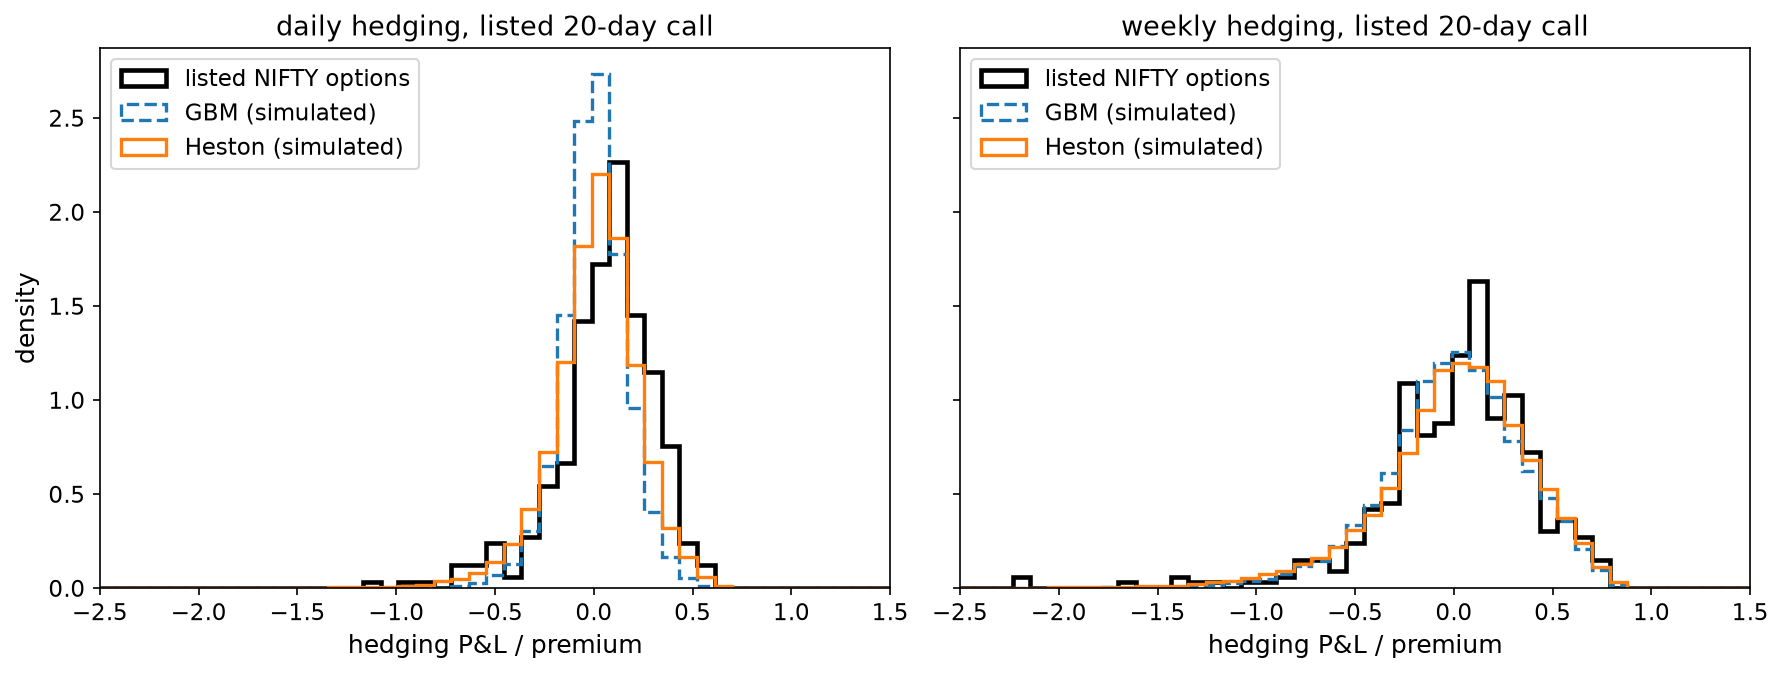

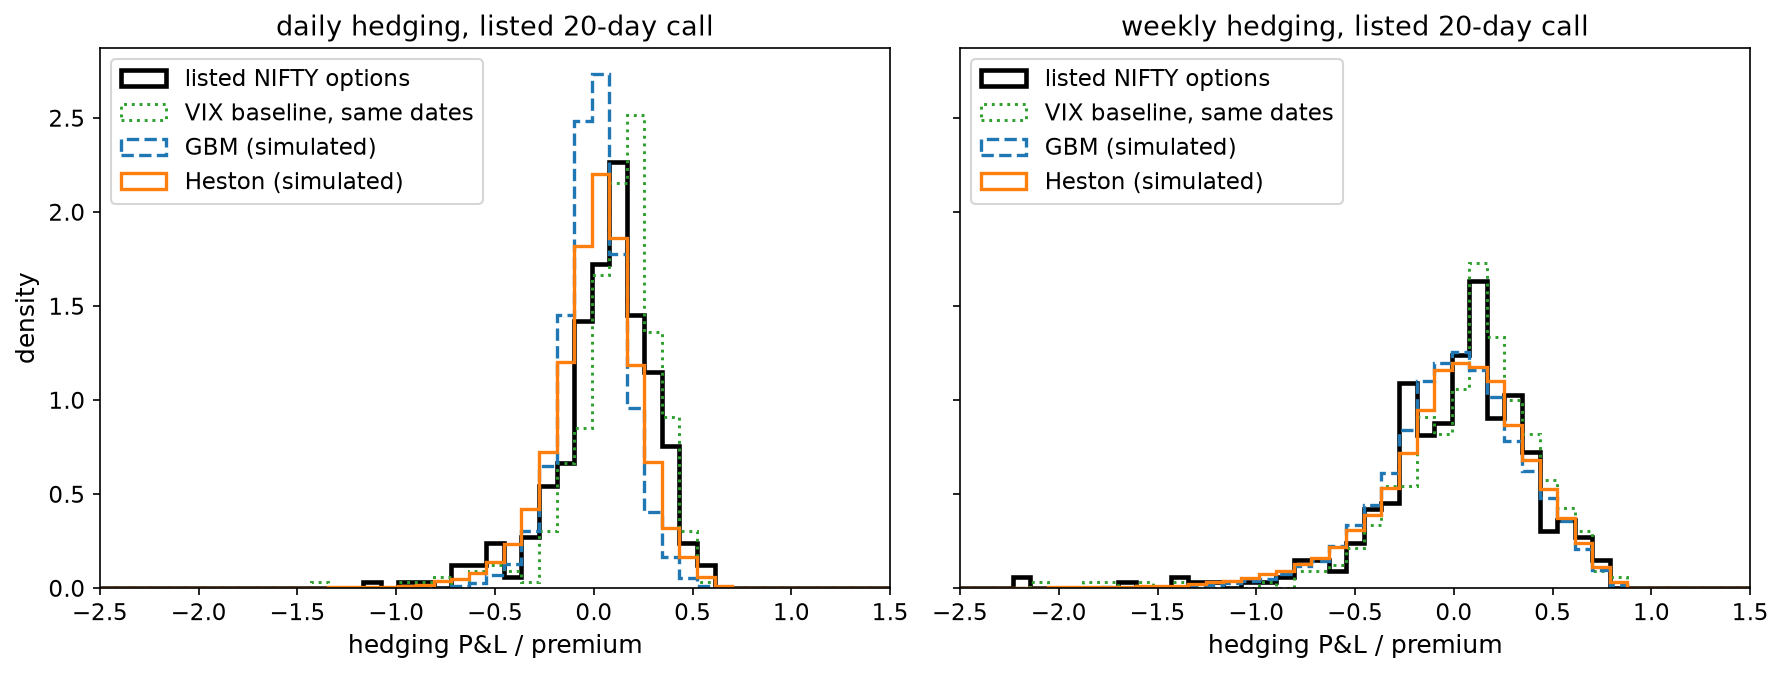

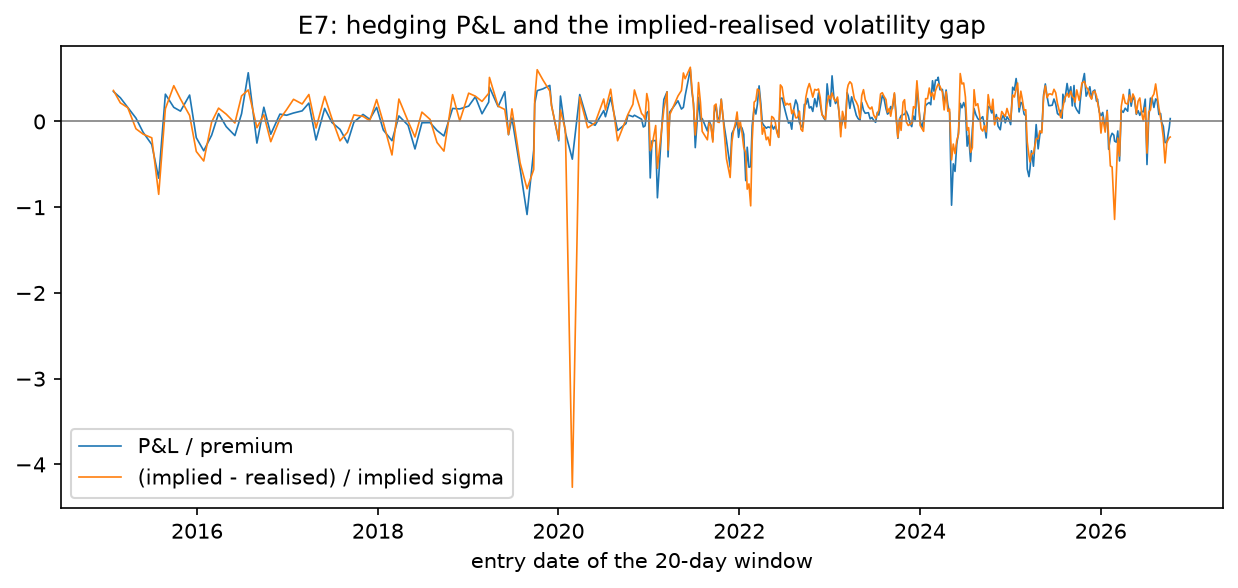

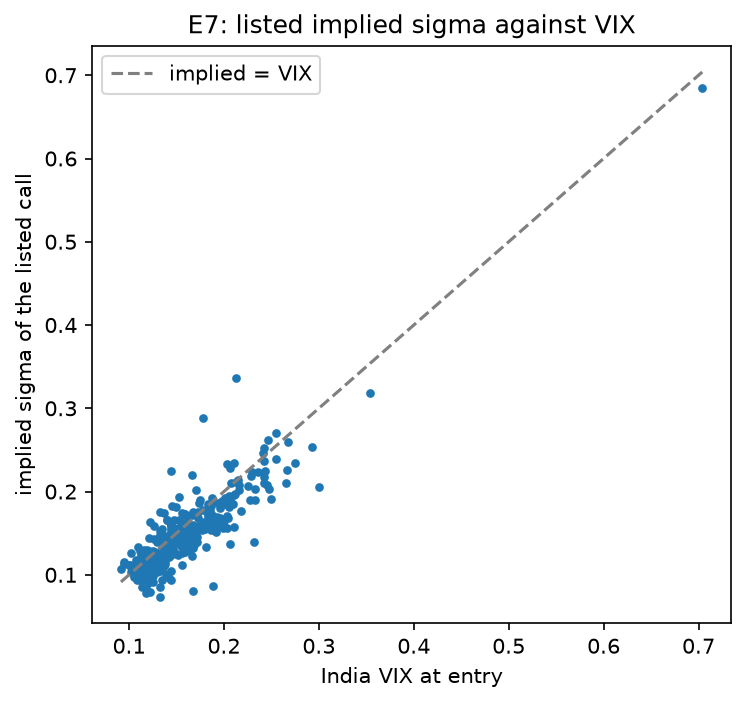

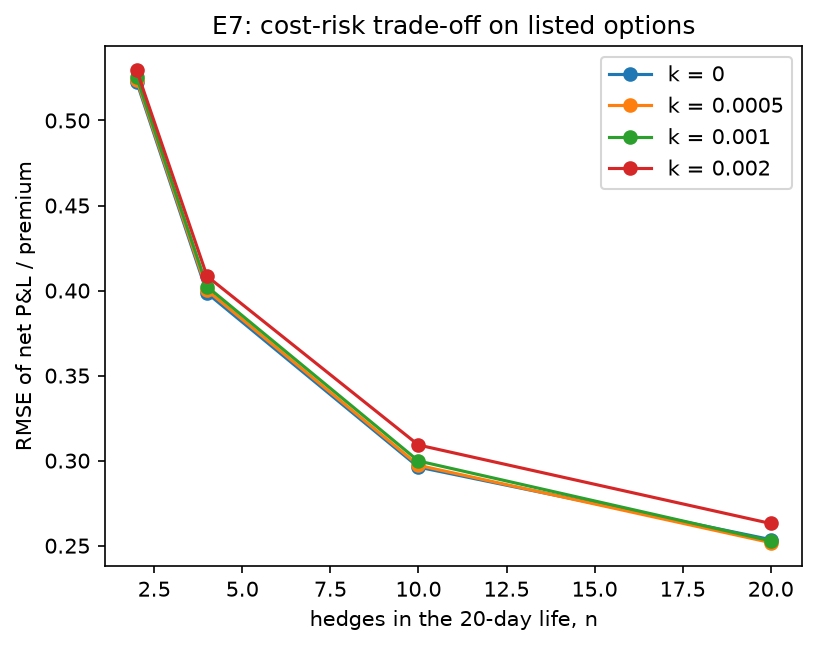

In [10]:
run_experiment("e7_backtest")
show_figures("e7_distribution", "e7_distribution_with_baseline", "e7_timeline", "e7_implied_vs_vix", "e7_costs")

**Interpretation.** Real listed NIFTY calls (372 windows, 2015 to 2026) are sold at their closing price and hedged along the real index path.
- **Mean.** The positive mean P&L is the E2 effect: implied volatility exceeded the realised volatility $\hat\sigma$ (the notes' formula) in about 68% of windows, and the E2 formula applied window by window explains most of the variation in the real P&L (correlation about 0.87; the timeline shows P&L tracking the implied-realised gap). The size of the mean depends on the assumed rate and dividend yield (about 0.05 per 2 percentage points of rate, see the rate and dividend table above), while the spread and shape hardly change.
- **Shape and tails.** The raw P&L is clearly larger and more skewed than GBM predicts. The gamma-weighted formula (each day's squared return weighted by that day's dollar gamma) explains the real P&L much better than the window-average $\hat\sigma$ (correlation 0.95 against 0.87) and removes the 26 February 2020 outlier, which was a crash that came when the option was far out of the money and its gamma was near zero. What is left over is the higher-order error of large single-day moves: in the 355 windows without a daily move above 4% it is as small as GBM's (0.041), and in the 17 windows with one it is about ten times larger. The formula uses each path's own squared returns, so it cannot separate Heston from GBM. The simulations use $\sigma = 14.8\%$ (the sample's mean implied volatility), $\alpha = r = 6\%$ and $T = 20/252$.
- **Costs.** Small round-trip costs (5 to 20 basis points, illustrative) remove the seller's average gain, and daily hedging still has the lowest RMSE for these 20-day options.
- **Baseline.** The VIX baseline gets the direction and rough size right (P&L correlation about 0.85 with the listed version, implied volatility correlation about 0.89 with VIX) but roughly doubles the mean gain and has heavier tails, so it is a stand-in for direction, not for tail risk.

## Test suite

In [11]:
result = subprocess.run([sys.executable, "-m", "pytest", str(ROOT / "tests"), "-q", "--color=no"], capture_output=True, text=True)
print(result.stdout)

............................                                             [100%]
28 passed in 19.15s



## Conclusions

1. Under GBM the discrete hedging error is unbiased and its standard deviation scales like $\sqrt{\Delta t}$ (fitted slope close to $-0.50$), a consequence of $\mathrm{Var}[(\Delta W)^2] = 2(\Delta t)^2$.
2. The seller's discounted P&L from a volatility error is $\tfrac12(\sigma_h^2 - \sigma^2)\int_0^Te^{-rt}S^2C_{xx}\,dt$, matching the El Karoui et al. formula in simulation and, via the implied-versus-realised gap, in the NIFTY backtest.
3. Under Heston and Merton dynamics the BSM hedge leaves residual risk that more frequent trading does not remove, with heavier left tails.
4. With proportional costs there is an interior optimal rebalancing frequency; Leland's expected-cost scaling is confirmed and pricing at $\hat\sigma_L$ removes the cost bias.
5. On real listed NIFTY options the hedging error is larger and more skewed than GBM predicts. Most of that is the gamma-weighted wrong-volatility effect, because implied and realised volatility differ from window to window; the rest comes from a few large single-day moves, and the data cannot separate Heston from GBM. Its mean is explained by implied volatility exceeding realised volatility, though its size depends on the assumed rate and dividend yield, and small trading costs remove it. A VIX-priced baseline reproduces the direction but overstates the mean gain and the tails.

## Limitations

- Listed prices are end-of-day closes (no intraday quotes or bid-ask). The older files have no underlying price and list only traded contracts, so the strike must be within 1% of the NIFTY close. There are about 130 independent windows, the 2020 crash is represented by only four, and the data cannot separate Heston from GBM. The 6% rate is assumed constant over twelve years and dividends are ignored in the base case, which moves the mean P&L materially (about 0.05 per 2 points of rate) but not the spread or shape.
- Heston and Merton parameters are illustrative and not calibrated to NIFTY.
- The optimal rebalancing frequency depends on the RMSE criterion.
- Backtest windows overlap, so there are far fewer independent observations than windows.

## References

Black and Scholes (1973); Merton (1973, 1976); Shreve, *Stochastic Calculus for Finance I and II* (2004); El Karoui, Jeanblanc-Picqué and Shreve (1998); Heston (1993); Leland (1985); Lord, Koekkoek and van Dijk (2010); Boyle and Emanuel (1980); Bertsimas, Kogan and Lo (2000); Hull, *Options, Futures, and Other Derivatives* (7th edition, 2009). Market data: NSE India F&O bhavcopy for NIFTY options (2015 to 2026), and NIFTY 50 and India VIX closes from Yahoo Finance (^NSEI, ^INDIAVIX) via yfinance, both downloaded 15 November 2026. Full citations are in `report/report.tex`.